INSTALLING LIBRARIES 

In [1]:
import numpy as np
import pandas as pd
import requests
import os

DATA LOADING 

In [128]:
kaggle_file = "/Users/snehasharma/Desktop/Agriculture_price_dataset.csv"

price_df = pd.read_csv(kaggle_file)

print("Kaggle dataset loaded successfully!")
print("Shape:", price_df.shape)
print("\nColumns:")
print(price_df.columns.tolist())

print("\nFirst 5 rows:")
print(price_df.head())

Kaggle dataset loaded successfully!
Shape: (737392, 10)

Columns:
['STATE', 'District Name', 'Market Name', 'Commodity', 'Variety', 'Grade', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price Date']

First 5 rows:
           STATE District Name        Market Name Commodity           Variety  \
0    Maharashtra        nashik  Lasalgaon(Niphad)     Wheat  Maharashtra 2189   
1    Maharashtra        satara              Patan    Tomato             Other   
2  Uttar Pradesh      mainpuri              Bewar    Potato             Local   
3      Rajasthan   chittorgarh          Nimbahera     Wheat             Other   
4      Rajasthan    pratapgarh         Pratapgarh     Onion             Other   

  Grade  Min_Price  Max_Price  Modal_Price Price Date  
0   FAQ     2172.0     2399.0       2300.0   6/6/2023  
1   FAQ     1000.0     1500.0       1250.0   6/6/2023  
2   FAQ      800.0      820.0        810.0   6/6/2023  
3   FAQ     2040.0     2668.0       2300.0   6/6/2023  
4   FAQ      476.0    

WILL BE ADDING THE REAL TIME DATA LATER


In [3]:
# Open-Meteo
latitude = 20.011
longitude = 73.790

weather_url = "https://archive-api.open-meteo.com/v1/archive"

weather_params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": "2023-06-06",
    "end_date": "2025-06-11",
    "daily": [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "rain_sum"
    ],
    "timezone": "Asia/Kolkata"
}

weather_response = requests.get(
    weather_url,
    params=weather_params
)

if weather_response.status_code == 200:
    weather_data = weather_response.json()

    weather_df = pd.DataFrame(
        weather_data["daily"]
    )

    print("Weather data loaded successfully!")
    print("Shape:", weather_df.shape)
    print(weather_df.head())

else:
    print(
        "Error:",
        weather_response.status_code
    )

Weather data loaded successfully!
Shape: (737, 4)
         time  temperature_2m_mean  relative_humidity_2m_mean  rain_sum
0  2023-06-06                 28.7                         63       0.0
1  2023-06-07                 29.1                         61       0.0
2  2023-06-08                 29.3                         60       0.0
3  2023-06-09                 29.2                         65       0.3
4  2023-06-10                 28.8                         64       1.7


In [4]:


os.makedirs("raw_data", exist_ok=True)

# Save price data exactly as loaded
price_df.to_csv(
    "raw_data/raw_price_data.csv",
    index=False
)

print("Raw price data saved successfully.")

Raw price data saved successfully.


In [5]:
clean_price_df = price_df.copy()


In [6]:


print("Duplicates before:", clean_price_df.duplicated().sum())

clean_price_df = clean_price_df.drop_duplicates()

print("Duplicates after:", clean_price_df.duplicated().sum())


Duplicates before: 0
Duplicates after: 0


In [7]:


print("\nMissing values before cleaning:")
print(clean_price_df.isnull().sum())


Missing values before cleaning:
STATE            0
District Name    0
Market Name      0
Commodity        0
Variety          0
Grade            0
Min_Price        0
Max_Price        0
Modal_Price      0
Price Date       0
dtype: int64


In [129]:




clean_price_df["Price Date"] = pd.to_datetime(
    clean_price_df["Price Date"],
    errors="coerce"
)



KeyError: 'Price Date'

In [9]:
# --------------------------------------------------
# 4. CONVERT PRICE COLUMNS TO NUMERIC
# --------------------------------------------------

price_columns = [
    "Min_Price",
    "Max_Price",
    "Modal_Price"
]

for col in price_columns:
    clean_price_df[col] = pd.to_numeric(
        clean_price_df[col],
        errors="coerce"
    )


In [10]:


for col in price_columns:
    clean_price_df.loc[
        clean_price_df[col] <= 0,
        col
    ] = np.nan


In [11]:


for col in price_columns:

    Q1 = clean_price_df[col].quantile(0.25)
    Q3 = clean_price_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    clean_price_df[f"{col}_outlier"] = (
        (clean_price_df[col] < lower_bound) |
        (clean_price_df[col] > upper_bound)
    )

print("\nOutlier counts:")

for col in price_columns:
    print(
        col,
        ":",
        clean_price_df[f"{col}_outlier"].sum()
    )




Outlier counts:
Min_Price : 27804
Max_Price : 37370
Modal_Price : 34617


In [12]:
clean_price_df = clean_price_df.rename(columns={
    "STATE": "State",
    "District Name": "District",
    "Market Name": "Market",
    "Price Date": "Date"
})

In [13]:


text_columns = [
    "State",
    "District",
    "Market",
    "Commodity",
    "Variety",
    "Grade"
]

for col in text_columns:
    clean_price_df[col] = (
        clean_price_df[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )


In [14]:


print("\nCleaned price dataset shape:")
print(clean_price_df.shape)

print("\nMissing values after cleaning:")
print(clean_price_df.isnull().sum())

display(clean_price_df.head())


Cleaned price dataset shape:
(737392, 13)

Missing values after cleaning:
State                    0
District                 0
Market                   0
Commodity                0
Variety                  0
Grade                    0
Min_Price              114
Max_Price              611
Modal_Price              3
Date                     0
Min_Price_outlier        0
Max_Price_outlier        0
Modal_Price_outlier      0
dtype: int64


,State,District,Market,Commodity,Variety,Grade,Min_Price,Max_Price,Modal_Price,Date,Min_Price_outlier,Max_Price_outlier,Modal_Price_outlier
0,Maharashtra,nashik,Lasalgaon(Niphad),Wheat,Maharashtra 2189,FAQ,2172.0,2399.0,2300.0,2023-06-06,False,False,False
1,Maharashtra,satara,Patan,Tomato,Other,FAQ,1000.0,1500.0,1250.0,2023-06-06,False,False,False
2,Uttar Pradesh,mainpuri,Bewar,Potato,Local,FAQ,800.0,820.0,810.0,2023-06-06,False,False,False
3,Rajasthan,chittorgarh,Nimbahera,Wheat,Other,FAQ,2040.0,2668.0,2300.0,2023-06-06,False,False,False
4,Rajasthan,pratapgarh,Pratapgarh,Onion,Other,FAQ,476.0,1043.0,617.0,2023-06-06,False,False,False


In [15]:

organized_price_df = clean_price_df.copy()

In [16]:


organized_price_df["Date"] = pd.to_datetime(
    organized_price_df["Date"],
    errors="coerce"
)


In [17]:


organized_price_df["Week"] = (
    organized_price_df["Date"]
    .dt.to_period("W")
    .apply(lambda x: x.start_time)
)

In [18]:


print("Organized dataset shape:")
print(organized_price_df.shape)

print("\nColumns:")
print(organized_price_df.columns.tolist())

display(organized_price_df.head())

Organized dataset shape:
(737392, 14)

Columns:
['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Min_Price', 'Max_Price', 'Modal_Price', 'Date', 'Min_Price_outlier', 'Max_Price_outlier', 'Modal_Price_outlier', 'Week']


,State,District,Market,Commodity,Variety,Grade,Min_Price,Max_Price,Modal_Price,Date,Min_Price_outlier,Max_Price_outlier,Modal_Price_outlier,Week
0,Maharashtra,nashik,Lasalgaon(Niphad),Wheat,Maharashtra 2189,FAQ,2172.0,2399.0,2300.0,2023-06-06,False,False,False,2023-06-05
1,Maharashtra,satara,Patan,Tomato,Other,FAQ,1000.0,1500.0,1250.0,2023-06-06,False,False,False,2023-06-05
2,Uttar Pradesh,mainpuri,Bewar,Potato,Local,FAQ,800.0,820.0,810.0,2023-06-06,False,False,False,2023-06-05
3,Rajasthan,chittorgarh,Nimbahera,Wheat,Other,FAQ,2040.0,2668.0,2300.0,2023-06-06,False,False,False,2023-06-05
4,Rajasthan,pratapgarh,Pratapgarh,Onion,Other,FAQ,476.0,1043.0,617.0,2023-06-06,False,False,False,2023-06-05


In [19]:


time_series_groups = (
    organized_price_df[
        ["State", "District", "Commodity", "Week"]
    ]
    .drop_duplicates()
    .sort_values(
        ["State", "District", "Commodity", "Week"]
    )
    .reset_index(drop=True)
)

print(
    "Number of unique State-District-Commodity-Week groups:",
    len(time_series_groups)
)

display(time_series_groups.head(20))

Number of unique State-District-Commodity-Week groups: 57866


,State,District,Commodity,Week
0,Andhra Pradesh,adilabad,Onion,2023-12-04
1,Andhra Pradesh,adilabad,Onion,2024-05-13
2,Andhra Pradesh,adilabad,Onion,2024-05-20
3,Andhra Pradesh,adilabad,Onion,2024-06-03
4,Andhra Pradesh,adilabad,Onion,2024-07-01
5,Andhra Pradesh,adilabad,Onion,2024-10-07
6,Andhra Pradesh,adilabad,Onion,2024-10-21
7,Andhra Pradesh,adilabad,Onion,2024-10-28
8,Andhra Pradesh,adilabad,Onion,2024-11-04
9,Andhra Pradesh,adilabad,Onion,2025-05-05


In [20]:


series_count = (
    organized_price_df
    .groupby(
        ["State", "District", "Commodity"]
    )
    .size()
    .reset_index(name="Observation_Count")
)

print("Number of separate time series:")
print(len(series_count))

display(series_count.head(20))

Number of separate time series:
1185


,State,District,Commodity,Observation_Count
0,Andhra Pradesh,adilabad,Onion,16
1,Andhra Pradesh,adilabad,Potato,13
2,Andhra Pradesh,adilabad,Tomato,137
3,Andhra Pradesh,adilabad,Wheat,8
4,Andhra Pradesh,hyderabad,Onion,2414
5,Andhra Pradesh,hyderabad,Potato,2402
6,Andhra Pradesh,hyderabad,Tomato,168
7,Andhra Pradesh,karimnagar,Potato,2
8,Andhra Pradesh,karimnagar,Tomato,33
9,Andhra Pradesh,krishna,Rice,106


In [21]:


organized_price_df.to_csv(
    "organized_price_data.csv",
    index=False
)

print("Step 4 completed successfully.")
print("Organized price data saved.")

Step 4 completed successfully.
Organized price data saved.


In [22]:

location_df = (
    organized_price_df[
        ["State", "District", "Market"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Number of unique locations:")
print(len(location_df))

display(location_df.head(20))

Number of unique locations:
1614


,State,District,Market
0,Maharashtra,nashik,Lasalgaon(Niphad)
1,Maharashtra,satara,Patan
2,Uttar Pradesh,mainpuri,Bewar
3,Rajasthan,chittorgarh,Nimbahera
4,Rajasthan,pratapgarh,Pratapgarh
5,Rajasthan,bharatpur,Bayana
6,Haryana,ambala,Naraingarh
7,Uttar Pradesh,pratapgarh,Pratapgarh
8,West Bengal,birbhum,Sainthia
9,Himachal Pradesh,mandi,Mandi(Takoli)


In [23]:


location_df = location_df.copy()

location_df["Location"] = (
    location_df["Market"].astype(str)
    + ", "
    + location_df["District"].astype(str)
    + ", "
    + location_df["State"].astype(str)
)

print("Location mapping table created:")
print(location_df.shape)

display(location_df.head(20))

Location mapping table created:
(1614, 4)


,State,District,Market,Location
0,Maharashtra,nashik,Lasalgaon(Niphad),"Lasalgaon(Niphad), nashik, Maharashtra"
1,Maharashtra,satara,Patan,"Patan, satara, Maharashtra"
2,Uttar Pradesh,mainpuri,Bewar,"Bewar, mainpuri, Uttar Pradesh"
3,Rajasthan,chittorgarh,Nimbahera,"Nimbahera, chittorgarh, Rajasthan"
4,Rajasthan,pratapgarh,Pratapgarh,"Pratapgarh, pratapgarh, Rajasthan"
5,Rajasthan,bharatpur,Bayana,"Bayana, bharatpur, Rajasthan"
6,Haryana,ambala,Naraingarh,"Naraingarh, ambala, Haryana"
7,Uttar Pradesh,pratapgarh,Pratapgarh,"Pratapgarh, pratapgarh, Uttar Pradesh"
8,West Bengal,birbhum,Sainthia,"Sainthia, birbhum, West Bengal"
9,Himachal Pradesh,mandi,Mandi(Takoli),"Mandi(Takoli), mandi, Himachal Pradesh"


In [24]:
print ('hello')

hello


In [25]:


import requests
import pandas as pd
import time

# Get unique districts
district_df = (
    organized_price_df[["State", "District"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Unique State-District locations:", len(district_df))


# Function to get coordinates
def get_coordinates(state, district):

    url = "https://geocoding-api.open-meteo.com/v1/search"

    params = {
        "name": district,
        "count": 1,
        "language": "en",
        "format": "json"
    }

    try:
        response = requests.get(
            url,
            params=params,
            timeout=10
        )

        if response.status_code == 200:

            data = response.json()

            if "results" in data and len(data["results"]) > 0:

                result = data["results"][0]

                return (
                    result.get("latitude"),
                    result.get("longitude")
                )

    except Exception:
        pass

    return None, None


# Get coordinates
coordinates = []

for i, row in district_df.iterrows():

    lat, lon = get_coordinates(
        row["State"],
        row["District"]
    )

    coordinates.append((lat, lon))

    if (i + 1) % 20 == 0:
        print(f"Processed {i + 1}/{len(district_df)} districts")

    time.sleep(0.1)


# Add coordinates
district_df["Latitude"] = [x[0] for x in coordinates]
district_df["Longitude"] = [x[1] for x in coordinates]


print("\nCoordinate mapping completed.")

display(district_df.head(20))

Unique State-District locations: 375
Processed 20/375 districts
Processed 40/375 districts
Processed 60/375 districts
Processed 80/375 districts
Processed 100/375 districts
Processed 120/375 districts
Processed 140/375 districts
Processed 160/375 districts
Processed 180/375 districts
Processed 200/375 districts
Processed 220/375 districts
Processed 240/375 districts
Processed 260/375 districts
Processed 280/375 districts
Processed 300/375 districts
Processed 320/375 districts
Processed 340/375 districts
Processed 360/375 districts

Coordinate mapping completed.


,State,District,Latitude,Longitude
0,Maharashtra,nashik,19.99727,73.79096
1,Maharashtra,satara,17.68589,73.99333
2,Uttar Pradesh,mainpuri,27.22857,79.02882
3,Rajasthan,chittorgarh,24.88963,74.62403
4,Rajasthan,pratapgarh,25.92058,81.99629
5,Rajasthan,bharatpur,27.68027,84.43647
6,Haryana,ambala,30.36099,76.79782
7,Uttar Pradesh,pratapgarh,25.92058,81.99629
8,West Bengal,birbhum,NaN,NaN
9,Himachal Pradesh,mandi,29.19344,72.85525


In [26]:
print("Missing Latitude:", district_df["Latitude"].isna().sum())
print("Missing Longitude:", district_df["Longitude"].isna().sum())

Missing Latitude: 26
Missing Longitude: 26


In [27]:
missing_coordinates = district_df[
    district_df["Latitude"].isna() |
    district_df["Longitude"].isna()
]

print("Locations with missing coordinates:", len(missing_coordinates))

display(missing_coordinates)

Locations with missing coordinates: 26


,State,District,Latitude,Longitude
8,West Bengal,birbhum,NaN,NaN
16,Meghalaya,west garo hills,NaN,NaN
27,Uttar Pradesh,bulandshahar,NaN,NaN
93,Uttar Pradesh,kaushambi,NaN,NaN
115,Chattisgarh,rajnandgaon,NaN,NaN
120,Madhya Pradesh,hoshangabad,NaN,NaN
127,West Bengal,paschim bardhaman,NaN,NaN
161,West Bengal,north 24 parganas,NaN,NaN
163,Gujarat,sabarkantha,NaN,NaN
185,Maharashtra,amarawati,NaN,NaN


In [28]:


manual_coordinates = {
    "birbhum": (23.8402, 87.6186),
    "west garo hills": (25.5138, 90.2028),
    "bulandshahar": (28.4069, 77.8498),
    "kaushambi": (25.5307, 81.3807),
    "rajnandgaon": (21.0971, 81.0287),
    "hoshangabad": (22.7441, 77.7360),
    "paschim bardhaman": (23.6850, 87.6600),
    "north 24 parganas": (22.6168, 88.4029),
    "sabarkantha": (23.5850, 73.0000),
    "amarawati": (20.9374, 77.7796),
    "alipurduar": (26.4919, 89.5270),
    "east khasi hills": (25.5377, 91.2999),
    "ambedkarnagar": (26.4400, 82.5500),
    "kamrup": (26.1445, 91.7362),
    "south garo hills": (25.3000, 90.6000),
    "west khasi hills": (25.6500, 90.2500),
    "north tripura": (24.3766, 92.1696),
    "east garo hills": (25.6000, 90.6000),
    "virudhunagar": (9.5680, 77.9624),
    "kancheepuram": (12.8342, 79.7036),
    "thirunelveli": (8.7139, 77.7567),
    "the nilgiris": (11.4102, 76.6950),
    "thiruchirappalli": (10.7905, 78.7047),
    "thiruvannamalai": (12.2253, 79.0747),
    "coochbehar": (26.3452, 89.4482)
}


for index, row in missing_coordinates.iterrows():

    district = row["District"].lower().strip()

    if district in manual_coordinates:

        district_df.loc[index, "Latitude"] = manual_coordinates[district][0]
        district_df.loc[index, "Longitude"] = manual_coordinates[district][1]


print("Missing Latitude:", district_df["Latitude"].isna().sum())
print("Missing Longitude:", district_df["Longitude"].isna().sum())

Missing Latitude: 0
Missing Longitude: 0


In [30]:
print("Successful locations:", len(weather_data_list))

Successful locations: 172


In [32]:


import time
import requests
import pandas as pd

successful_locations = len(weather_data_list)

print("Already successful:", successful_locations)
print("Total locations:", len(district_df))

# Find districts that are not already in weather_data_list
successful_keys = set()

for df in weather_data_list:
    for _, r in df[["State", "District"]].drop_duplicates().iterrows():
        successful_keys.add(
            (r["State"], r["District"])
        )

remaining_locations = district_df[
    ~district_df.apply(
        lambda row: (row["State"], row["District"]) in successful_keys,
        axis=1
    )
].reset_index(drop=True)

print("Locations remaining:", len(remaining_locations))


for i, row in remaining_locations.iterrows():

    weather_url = "https://archive-api.open-meteo.com/v1/archive"

    weather_params = {
        "latitude": row["Latitude"],
        "longitude": row["Longitude"],
        "start_date": start_date,
        "end_date": end_date,
        "daily": [
            "temperature_2m_mean",
            "relative_humidity_2m_mean",
            "rain_sum"
        ],
        "timezone": "Asia/Kolkata"
    }

    success = False

    for attempt in range(3):

        try:
            response = requests.get(
                weather_url,
                params=weather_params,
                timeout=30
            )

            if response.status_code == 200:

                data = response.json()
                daily = data["daily"]

                temp_df = pd.DataFrame({
                    "Date": pd.to_datetime(daily["time"]),
                    "Temperature": daily["temperature_2m_mean"],
                    "Humidity": daily["relative_humidity_2m_mean"],
                    "Rainfall": daily["rain_sum"]
                })

                temp_df["State"] = row["State"]
                temp_df["District"] = row["District"]
                temp_df["Latitude"] = row["Latitude"]
                temp_df["Longitude"] = row["Longitude"]

                weather_data_list.append(temp_df)

                success = True
                break

            elif response.status_code == 429:
                print(
                    f"429 for {row['District']} — "
                    f"waiting before retry {attempt + 1}/3"
                )
                time.sleep(10)

            else:
                print(
                    f"Error {response.status_code} "
                    f"for {row['District']}"
                )
                break

        except Exception as e:
            print(f"Error for {row['District']}: {e}")
            time.sleep(5)

    if (i + 1) % 10 == 0:
        print(
            f"Retry progress: "
            f"{i + 1}/{len(remaining_locations)}"
        )

    # Delay between API requests
    time.sleep(3)


# Combine all successful weather data
weather_df = pd.concat(
    weather_data_list,
    ignore_index=True
)

print("\nWeather data completed!")
print("Weather dataset shape:", weather_df.shape)

display(weather_df.head())


Already successful: 186
Total locations: 375
Locations remaining: 189
Retry progress: 10/189
Retry progress: 20/189
Retry progress: 30/189
Retry progress: 40/189
Retry progress: 50/189
Retry progress: 60/189
Retry progress: 70/189
Retry progress: 80/189
Retry progress: 90/189
Retry progress: 100/189
Retry progress: 110/189
Retry progress: 120/189
429 for araria — waiting before retry 1/3
429 for araria — waiting before retry 2/3
429 for araria — waiting before retry 3/3
Retry progress: 130/189
429 for bhojpur — waiting before retry 1/3
429 for bhojpur — waiting before retry 2/3
429 for bhojpur — waiting before retry 3/3
429 for samastipur — waiting before retry 1/3
429 for samastipur — waiting before retry 2/3
429 for samastipur — waiting before retry 3/3
429 for west khasi hills — waiting before retry 1/3
429 for west khasi hills — waiting before retry 2/3
429 for west khasi hills — waiting before retry 3/3


KeyboardInterrupt: 

In [33]:


import time
import requests
import pandas as pd

# Find locations already completed
successful_keys = set()

for df in weather_data_list:
    for _, r in df[["State", "District"]].drop_duplicates().iterrows():
        successful_keys.add(
            (r["State"], r["District"])
        )

# Remaining locations only
remaining_locations = district_df[
    ~district_df.apply(
        lambda row: (row["State"], row["District"]) in successful_keys,
        axis=1
    )
].reset_index(drop=True)

print("Already completed:", len(successful_keys))
print("Remaining locations:", len(remaining_locations))


# Process in batches
batch_size = 20

for start in range(0, len(remaining_locations), batch_size):

    batch = remaining_locations.iloc[
        start:start + batch_size
    ]

    latitudes = ",".join(
        batch["Latitude"].astype(str)
    )

    longitudes = ",".join(
        batch["Longitude"].astype(str)
    )

    weather_url = "https://archive-api.open-meteo.com/v1/archive"

    weather_params = {
        "latitude": latitudes,
        "longitude": longitudes,
        "start_date": start_date,
        "end_date": end_date,
        "daily": [
            "temperature_2m_mean",
            "relative_humidity_2m_mean",
            "rain_sum"
        ],
        "timezone": "Asia/Kolkata"
    }

    try:

        response = requests.get(
            weather_url,
            params=weather_params,
            timeout=60
        )

        if response.status_code == 200:

            batch_weather = response.json()

            # Open-Meteo returns one result per coordinate
            for j, location_weather in enumerate(batch_weather):

                daily = location_weather["daily"]

                temp_df = pd.DataFrame({
                    "Date": pd.to_datetime(daily["time"]),
                    "Temperature": daily["temperature_2m_mean"],
                    "Humidity": daily["relative_humidity_2m_mean"],
                    "Rainfall": daily["rain_sum"]
                })

                temp_df["State"] = batch.iloc[j]["State"]
                temp_df["District"] = batch.iloc[j]["District"]
                temp_df["Latitude"] = batch.iloc[j]["Latitude"]
                temp_df["Longitude"] = batch.iloc[j]["Longitude"]

                weather_data_list.append(temp_df)

            print(
                f"Processed {min(start + batch_size, len(remaining_locations))}"
                f"/{len(remaining_locations)}"
            )

        else:

            print(
                f"Batch error: {response.status_code}"
            )

    except Exception as e:

        print("Batch error:", e)

    # Small pause between batches
    time.sleep(3)


# Combine everything
weather_df = pd.concat(
    weather_data_list,
    ignore_index=True
)

print("\nWeather data completed!")
print("Weather dataset shape:", weather_df.shape)

display(weather_df.head())

Already completed: 315
Remaining locations: 60
Batch error: 429
Batch error: 429
Batch error: 429


KeyboardInterrupt: 

In [35]:
import requests
import time
import pandas as pd


successful_keys = set()

for item in weather_data_list:

    if len(item) > 0:
        state = item["State"].iloc[0]
        district = item["District"].iloc[0]

        successful_keys.add(
            (state, district)
        )

print("Already completed:", len(successful_keys))


# --------------------------------------------------
# 2. Find remaining locations
# --------------------------------------------------

remaining_locations = district_df[
    ~district_df.apply(
        lambda row: (row["State"], row["District"]) in successful_keys,
        axis=1
    )
].copy()

print("Total locations:", len(district_df))
print("Remaining locations:", len(remaining_locations))


# --------------------------------------------------
# 3. Date range
# --------------------------------------------------

start_date = organized_price_df["Date"].min().strftime("%Y-%m-%d")
end_date = organized_price_df["Date"].max().strftime("%Y-%m-%d")

print("Weather period:", start_date, "to", end_date)


# --------------------------------------------------
# 4. Fetch remaining weather data
# --------------------------------------------------

for count, (_, row) in enumerate(
    remaining_locations.iterrows(),
    start=1
):

    weather_url = "https://archive-api.open-meteo.com/v1/archive"

    weather_params = {
        "latitude": row["Latitude"],
        "longitude": row["Longitude"],
        "start_date": start_date,
        "end_date": end_date,
        "daily": [
            "temperature_2m_mean",
            "relative_humidity_2m_mean",
            "rain_sum"
        ],
        "timezone": "Asia/Kolkata"
    }

    try:

        response = requests.get(
            weather_url,
            params=weather_params,
            timeout=60
        )

    

        if response.status_code == 200:

            data = response.json()

            daily = data.get("daily", {})

            weather_df = pd.DataFrame({
                "Date": daily.get("time", []),
                "Temperature": daily.get(
                    "temperature_2m_mean", []
                ),
                "Humidity": daily.get(
                    "relative_humidity_2m_mean", []
                ),
                "Rainfall": daily.get(
                    "rain_sum", []
                )
            })

            weather_df["State"] = row["State"]
            weather_df["District"] = row["District"]

            weather_df = weather_df[
                [
                    "State",
                    "District",
                    "Date",
                    "Temperature",
                    "Humidity",
                    "Rainfall"
                ]
            ]

            weather_data_list.append(weather_df)

            print(
                f"{count}/{len(remaining_locations)} completed: "
                f"{row['State']} - {row['District']}"
            )



        elif response.status_code == 429:

            print("\n429 RATE LIMIT HIT.")
            print("Stopping here to protect completed data.")
            break

      

        else:

            print(
                f"Error {response.status_code}: "
                f"{row['State']} - {row['District']}"
            )

    except Exception as e:

        print(
            f"Request failed: "
            f"{row['State']} - {row['District']} | {e}"
        )

    # Wait before next request
    time.sleep(8)




final_successful_keys = set()

for item in weather_data_list:

    if len(item) > 0:

        state = item["State"].iloc[0]
        district = item["District"].iloc[0]

        final_successful_keys.add(
            (state, district)
        )

print("\nFinished.")
print("-----------------------------")
print(
    "Weather locations collected:",
    len(final_successful_keys)
)
print(
    "Total locations:",
    len(district_df)
)
print(
    "Remaining:",
    len(district_df) - len(final_successful_keys)
)
print("-----------------------------")

Already completed: 315
Total locations: 375
Remaining locations: 60
Weather period: 2023-06-06 to 2025-06-11
1/60 completed: Bihar - araria
2/60 completed: Bihar - bhojpur
3/60 completed: Bihar - samastipur
4/60 completed: Meghalaya - west khasi hills
5/60 completed: Bihar - sheohar
6/60 completed: Bihar - banka
7/60 completed: Tamilnadu - namakkal
8/60 completed: Bihar - jamui
9/60 completed: Bihar - madhepura
10/60 completed: Bihar - rohtas
11/60 completed: Bihar - buxar
12/60 completed: Bihar - darbhanga
13/60 completed: Orissa - cuttack
14/60 completed: Bihar - khagaria
15/60 completed: Bihar - patna
16/60 completed: Chattisgarh - dhamtari
17/60 completed: Rajasthan - nagaur
18/60 completed: Tamilnadu - salem
19/60 completed: Andhra Pradesh - nizamabad
20/60 completed: Tripura - north tripura
21/60 completed: Meghalaya - east garo hills
22/60 completed: Nagaland - wokha
23/60 completed: Tamilnadu - thiruvarur
24/60 completed: Tamilnadu - theni
25/60 completed: Tamilnadu - nagapatti

In [36]:

weekly_price_df = organized_price_df.copy()

# Make sure price columns are numeric
weekly_price_df["Min_Price"] = pd.to_numeric(
    weekly_price_df["Min_Price"],
    errors="coerce"
)

weekly_price_df["Max_Price"] = pd.to_numeric(
    weekly_price_df["Max_Price"],
    errors="coerce"
)

weekly_price_df["Modal_Price"] = pd.to_numeric(
    weekly_price_df["Modal_Price"],
    errors="coerce"
)

# Weekly aggregation
weekly_price_df = (
    weekly_price_df
    .groupby(
        [
            "State",
            "District",
            "Commodity",
            "Week"
        ],
        as_index=False
    )
    .agg(
        Median_Modal_Price=("Modal_Price", "median"),
        Median_Min_Price=("Min_Price", "median"),
        Median_Max_Price=("Max_Price", "median")
    )
)

# Sort the resulting time series
weekly_price_df = weekly_price_df.sort_values(
    [
        "State",
        "District",
        "Commodity",
        "Week"
    ]
).reset_index(drop=True)

# Check result
print("Weekly price dataset shape:", weekly_price_df.shape)

print("\nColumns:")
print(weekly_price_df.columns.tolist())

print("\nFirst 10 rows:")
display(weekly_price_df.head(10))

Weekly price dataset shape: (57866, 7)

Columns:
['State', 'District', 'Commodity', 'Week', 'Median_Modal_Price', 'Median_Min_Price', 'Median_Max_Price']

First 10 rows:


,State,District,Commodity,Week,Median_Modal_Price,Median_Min_Price,Median_Max_Price
0,Andhra Pradesh,adilabad,Onion,2023-12-04,2000.0,2000.0,2000.0
1,Andhra Pradesh,adilabad,Onion,2024-05-13,3250.0,3250.0,3250.0
2,Andhra Pradesh,adilabad,Onion,2024-05-20,2500.0,2500.0,2500.0
3,Andhra Pradesh,adilabad,Onion,2024-06-03,2500.0,2500.0,2500.0
4,Andhra Pradesh,adilabad,Onion,2024-07-01,5000.0,5000.0,5000.0
5,Andhra Pradesh,adilabad,Onion,2024-10-07,825.0,625.0,1000.0
6,Andhra Pradesh,adilabad,Onion,2024-10-21,743.5,675.0,812.5
7,Andhra Pradesh,adilabad,Onion,2024-10-28,793.5,775.0,812.5
8,Andhra Pradesh,adilabad,Onion,2024-11-04,950.0,900.0,1000.0
9,Andhra Pradesh,adilabad,Onion,2025-05-05,700.0,600.0,800.0


In [37]:



weather_df = pd.concat(
    weather_data_list,
    ignore_index=True
)

# Convert Date to datetime
weather_df["Date"] = pd.to_datetime(
    weather_df["Date"],
    errors="coerce"
)

# Create Week column
weather_df["Week"] = (
    weather_df["Date"]
    .dt.to_period("W")
    .apply(lambda x: x.start_time)
)

# Make sure weather values are numeric
weather_df["Temperature"] = pd.to_numeric(
    weather_df["Temperature"],
    errors="coerce"
)

weather_df["Humidity"] = pd.to_numeric(
    weather_df["Humidity"],
    errors="coerce"
)

weather_df["Rainfall"] = pd.to_numeric(
    weather_df["Rainfall"],
    errors="coerce"
)

# Weekly weather aggregation
weekly_weather_df = (
    weather_df
    .groupby(
        [
            "District",
            "Week"
        ],
        as_index=False
    )
    .agg(
        Total_Rainfall=("Rainfall", "sum"),
        Mean_Temperature=("Temperature", "mean"),
        Mean_Humidity=("Humidity", "mean")
    )
)

# Sort
weekly_weather_df = weekly_weather_df.sort_values(
    [
        "District",
        "Week"
    ]
).reset_index(drop=True)

# Check result
print("Weather dataset shape:", weather_df.shape)

print("\nWeekly weather dataset shape:",
      weekly_weather_df.shape)

print("\nColumns:")
print(weekly_weather_df.columns.tolist())

print("\nFirst 10 rows:")
display(weekly_weather_df.head(10))

Weather dataset shape: (276375, 9)

Weekly weather dataset shape: (39538, 5)

Columns:
['District', 'Week', 'Total_Rainfall', 'Mean_Temperature', 'Mean_Humidity']

First 10 rows:


,District,Week,Total_Rainfall,Mean_Temperature,Mean_Humidity
0,adilabad,2023-06-05,3.6,34.866667,35.833333
1,adilabad,2023-06-12,4.0,34.857143,36.142857
2,adilabad,2023-06-19,12.2,32.071429,53.571429
3,adilabad,2023-06-26,52.2,28.071429,74.428571
4,adilabad,2023-07-03,48.2,28.442857,76.142857
5,adilabad,2023-07-10,83.7,27.114286,81.142857
6,adilabad,2023-07-17,268.0,26.057143,86.857143
7,adilabad,2023-07-24,135.3,26.942857,82.285714
8,adilabad,2023-07-31,12.6,27.385714,75.571429
9,adilabad,2023-08-07,2.7,27.785714,71.857143


In [38]:


# Merge using District + Week
merged_df = weekly_price_df.merge(
    weekly_weather_df,
    on=["District", "Week"],
    how="left"
)

# Sort the merged dataset
merged_df = merged_df.sort_values(
    [
        "State",
        "District",
        "Commodity",
        "Week"
    ]
).reset_index(drop=True)

# Check result
print("Merged dataset shape:", merged_df.shape)

print("\nColumns:")
print(merged_df.columns.tolist())

print("\nMissing weather values:")
print(
    merged_df[
        [
            "Total_Rainfall",
            "Mean_Temperature",
            "Mean_Humidity"
        ]
    ].isnull().sum()
)

print("\nFirst 10 rows:")
display(merged_df.head(10))

Merged dataset shape: (57866, 10)

Columns:
['State', 'District', 'Commodity', 'Week', 'Median_Modal_Price', 'Median_Min_Price', 'Median_Max_Price', 'Total_Rainfall', 'Mean_Temperature', 'Mean_Humidity']

Missing weather values:
Total_Rainfall      0
Mean_Temperature    0
Mean_Humidity       0
dtype: int64

First 10 rows:


,State,District,Commodity,Week,Median_Modal_Price,Median_Min_Price,Median_Max_Price,Total_Rainfall,Mean_Temperature,Mean_Humidity
0,Andhra Pradesh,adilabad,Onion,2023-12-04,2000.0,2000.0,2000.0,3.6,22.628571,76.428571
1,Andhra Pradesh,adilabad,Onion,2024-05-13,3250.0,3250.0,3250.0,6.9,30.871429,58.142857
2,Andhra Pradesh,adilabad,Onion,2024-05-20,2500.0,2500.0,2500.0,5.1,33.800000,49.142857
3,Andhra Pradesh,adilabad,Onion,2024-06-03,2500.0,2500.0,2500.0,24.1,31.285714,61.857143
4,Andhra Pradesh,adilabad,Onion,2024-07-01,5000.0,5000.0,5000.0,38.7,28.071429,75.285714
5,Andhra Pradesh,adilabad,Onion,2024-10-07,825.0,625.0,1000.0,45.4,26.514286,81.285714
6,Andhra Pradesh,adilabad,Onion,2024-10-21,743.5,675.0,812.5,0.0,25.885714,70.142857
7,Andhra Pradesh,adilabad,Onion,2024-10-28,793.5,775.0,812.5,5.9,26.642857,70.000000
8,Andhra Pradesh,adilabad,Onion,2024-11-04,950.0,900.0,1000.0,0.0,25.185714,60.142857
9,Andhra Pradesh,adilabad,Onion,2025-05-05,700.0,600.0,800.0,0.0,32.242857,38.571429


In [39]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make a copy for EDA
eda_df = merged_df.copy()

# Make sure Week is datetime
eda_df["Week"] = pd.to_datetime(eda_df["Week"])

print("EDA dataset shape:", eda_df.shape)

print("\nDataset information:")
print(eda_df.info())

print("\nMissing values:")
print(eda_df.isnull().sum())

print("\nNumber of unique values:")
print("States:", eda_df["State"].nunique())
print("Districts:", eda_df["District"].nunique())
print("Commodities:", eda_df["Commodity"].nunique())
print("Weeks:", eda_df["Week"].nunique())

print("\nDate range:")
print("From:", eda_df["Week"].min())
print("To:", eda_df["Week"].max())

EDA dataset shape: (57866, 10)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57866 entries, 0 to 57865
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   State               57866 non-null  string        
 1   District            57866 non-null  object        
 2   Commodity           57866 non-null  string        
 3   Week                57866 non-null  datetime64[ns]
 4   Median_Modal_Price  57866 non-null  float64       
 5   Median_Min_Price    57865 non-null  float64       
 6   Median_Max_Price    57856 non-null  float64       
 7   Total_Rainfall      57866 non-null  float64       
 8   Mean_Temperature    57866 non-null  float64       
 9   Mean_Humidity       57866 non-null  float64       
dtypes: datetime64[ns](1), float64(6), object(1), string(2)
memory usage: 4.4+ MB
None

Missing values:
State                  0
District               0
Commodity   

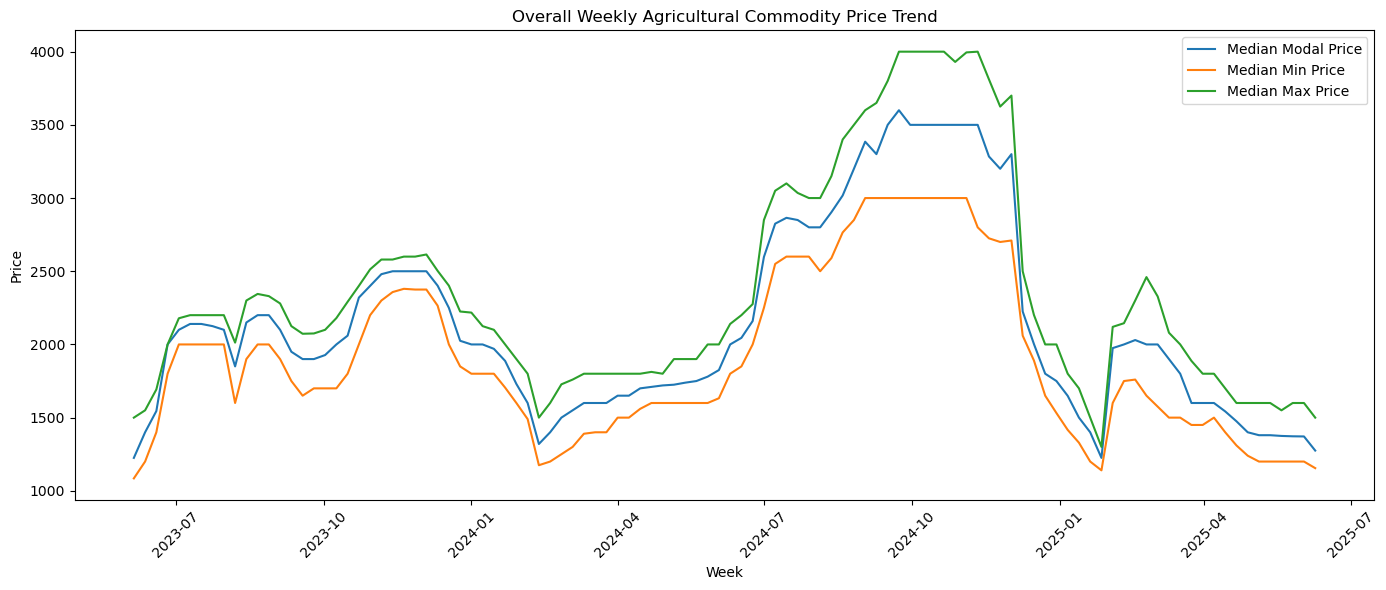

In [40]:

overall_price_trend = (
    eda_df
    .groupby("Week", as_index=False)
    .agg(
        Median_Modal_Price=("Median_Modal_Price", "median"),
        Median_Min_Price=("Median_Min_Price", "median"),
        Median_Max_Price=("Median_Max_Price", "median")
    )
)

# Plot overall trend
plt.figure(figsize=(14, 6))

plt.plot(
    overall_price_trend["Week"],
    overall_price_trend["Median_Modal_Price"],
    label="Median Modal Price"
)

plt.plot(
    overall_price_trend["Week"],
    overall_price_trend["Median_Min_Price"],
    label="Median Min Price"
)

plt.plot(
    overall_price_trend["Week"],
    overall_price_trend["Median_Max_Price"],
    label="Median Max Price"
)

plt.xlabel("Week")
plt.ylabel("Price")
plt.title("Overall Weekly Agricultural Commodity Price Trend")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Commodity-wise price summary:


,Commodity,Median_Price,Mean_Price,Record_Count
2,Rice,3300.0,3605.806511,814
3,Tomato,2800.0,4057.252164,3581
4,Wheat,2400.0,2463.748793,6006
0,Onion,2200.0,2583.747518,22647
1,Potato,1580.0,1859.509963,24818


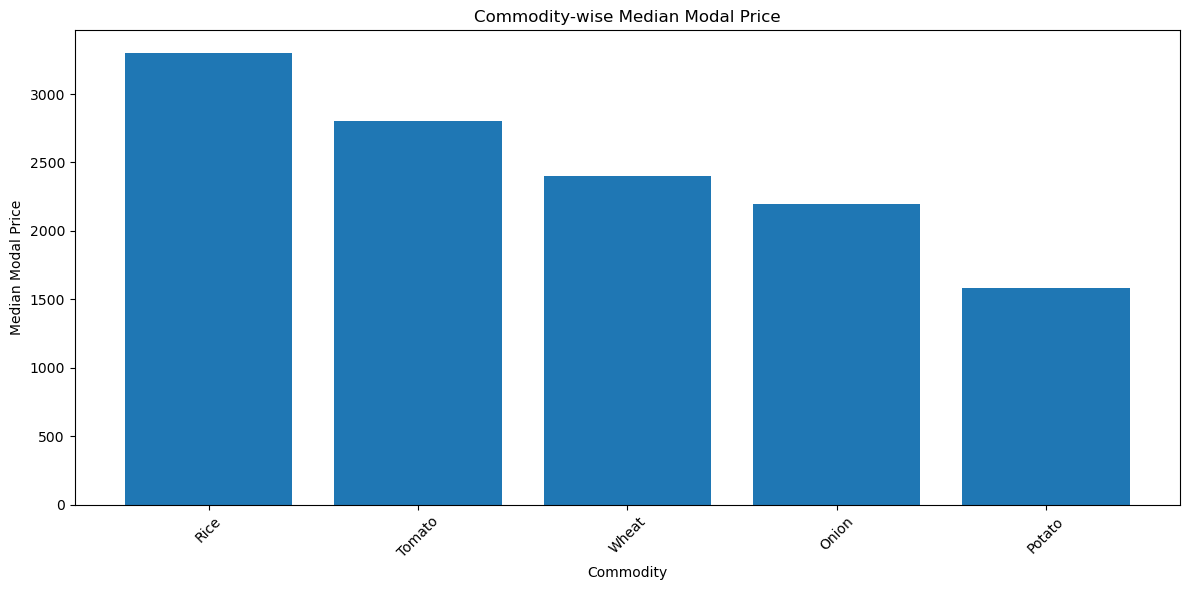

In [41]:


commodity_price = (
    eda_df
    .groupby("Commodity", as_index=False)
    .agg(
        Median_Price=("Median_Modal_Price", "median"),
        Mean_Price=("Median_Modal_Price", "mean"),
        Record_Count=("Median_Modal_Price", "count")
    )
    .sort_values("Median_Price", ascending=False)
)

print("Commodity-wise price summary:")
display(commodity_price)

# Plot median modal price by commodity
plt.figure(figsize=(12, 6))

plt.bar(
    commodity_price["Commodity"],
    commodity_price["Median_Price"]
)

plt.xlabel("Commodity")
plt.ylabel("Median Modal Price")
plt.title("Commodity-wise Median Modal Price")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

State-wise price summary:


,State,Median_Price,Mean_Price,Record_Count
23,Tamil Nadu,6000.0,6506.250000,16
24,Tamilnadu,4600.0,4500.942687,2181
25,Tripura,4175.0,4206.250000,8
19,Nagaland,4000.0,4418.660287,627
17,Manipur,3750.0,3971.100279,359
14,Kerala,3700.0,4006.610599,1736
18,Meghalaya,2925.0,3336.554622,238
20,Orissa,2650.0,3080.547141,2641
0,Andhra Pradesh,2500.0,2712.383481,1017
2,Bihar,2400.0,2728.530488,2132


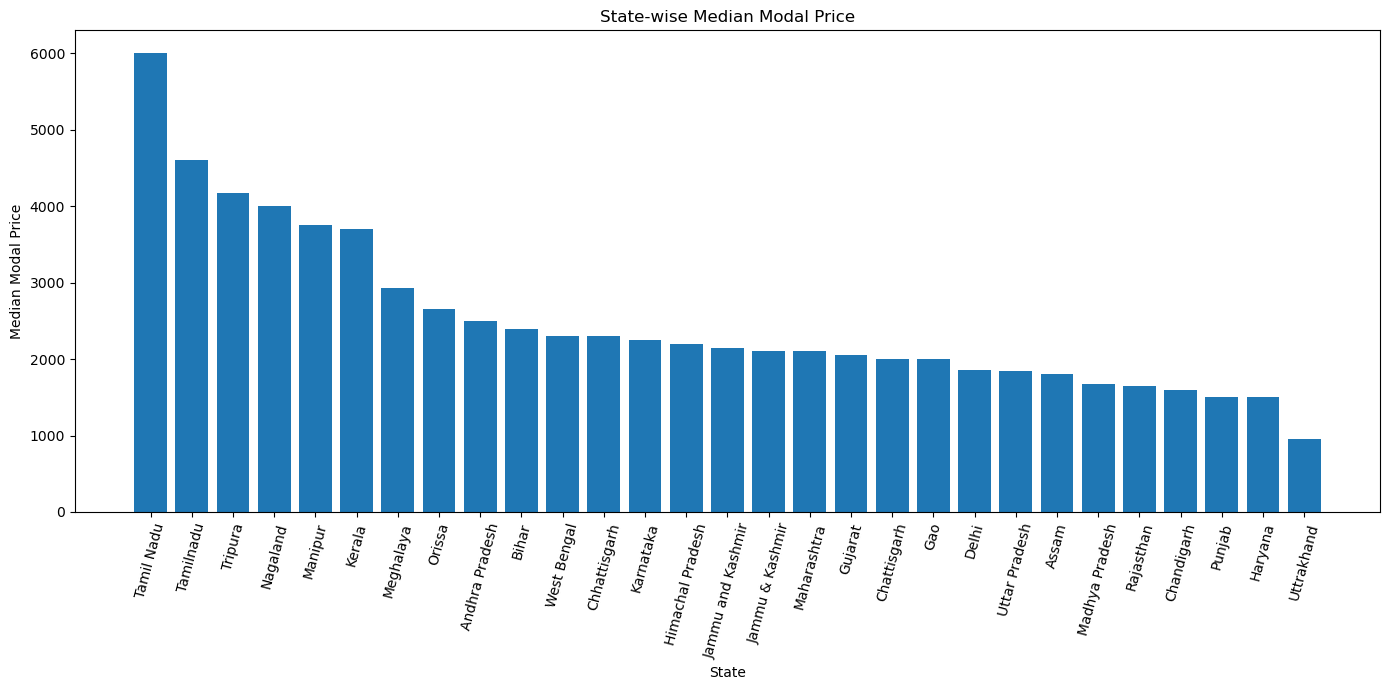

In [42]:


state_price = (
    eda_df
    .groupby("State", as_index=False)
    .agg(
        Median_Price=("Median_Modal_Price", "median"),
        Mean_Price=("Median_Modal_Price", "mean"),
        Record_Count=("Median_Modal_Price", "count")
    )
    .sort_values("Median_Price", ascending=False)
)

print("State-wise price summary:")
display(state_price)

# Plot
plt.figure(figsize=(14, 7))

plt.bar(
    state_price["State"],
    state_price["Median_Price"]
)

plt.xlabel("State")
plt.ylabel("Median Modal Price")
plt.title("State-wise Median Modal Price")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [43]:


state_mapping = {
    "Tamilnadu": "Tamil Nadu",
    "Chattisgarh": "Chhattisgarh",
    "Jammu & Kashmir": "Jammu and Kashmir",
    "Gao": "Goa",
    "Uttrakhand": "Uttarakhand"
}

eda_df["State"] = eda_df["State"].replace(state_mapping)

# Check corrected state names
print("Unique states after standardization:")
print(sorted(eda_df["State"].unique()))

print("\nTotal unique states:", eda_df["State"].nunique())

Unique states after standardization:
['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Nagaland', 'Orissa', 'Punjab', 'Rajasthan', 'Tamil Nadu', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Total unique states: 26


Updated State-wise price summary:


,State,Median_Price,Mean_Price,Record_Count
21,Tamil Nadu,4600.0,4515.546655,2197
22,Tripura,4175.0,4206.250000,8
17,Nagaland,4000.0,4418.660287,627
15,Manipur,3750.0,3971.100279,359
12,Kerala,3700.0,4006.610599,1736
16,Meghalaya,2925.0,3336.554622,238
18,Orissa,2650.0,3080.547141,2641
0,Andhra Pradesh,2500.0,2712.383481,1017
2,Bihar,2400.0,2728.530488,2132
25,West Bengal,2300.0,2603.085570,2869


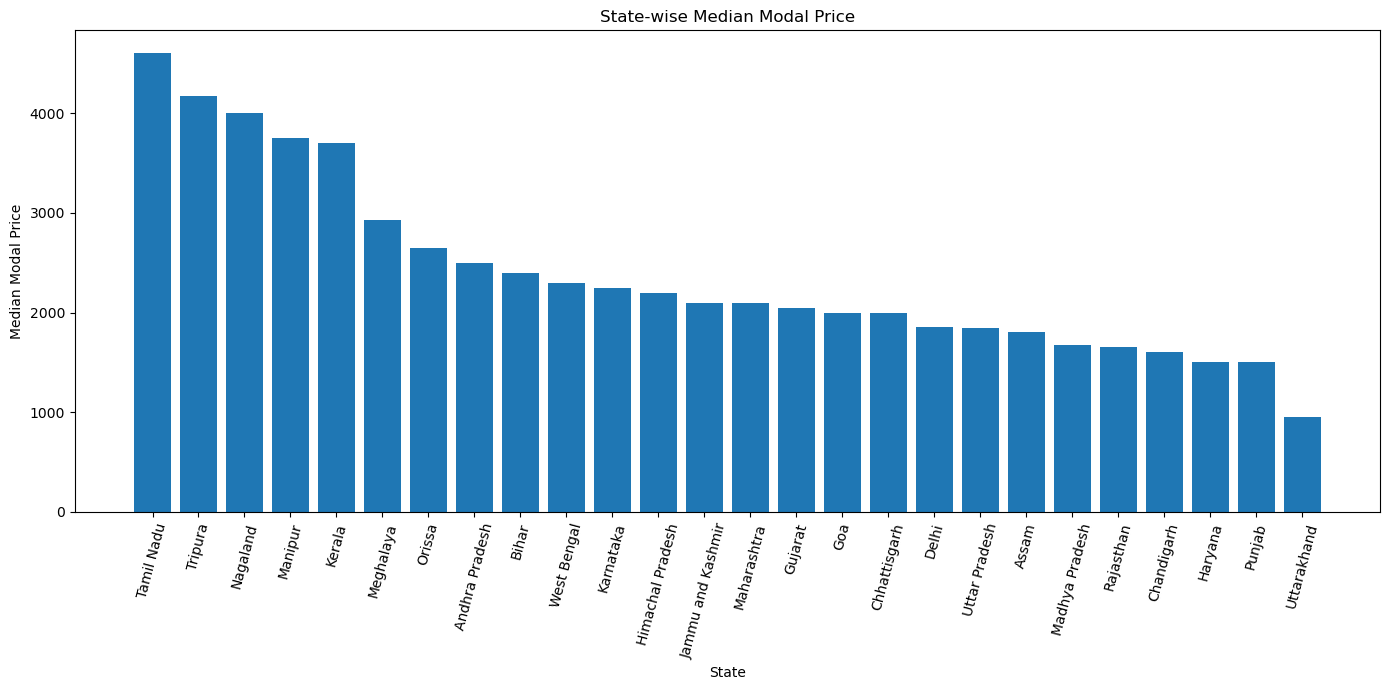

In [44]:

state_price = (
    eda_df
    .groupby("State", as_index=False)
    .agg(
        Median_Price=("Median_Modal_Price", "median"),
        Mean_Price=("Median_Modal_Price", "mean"),
        Record_Count=("Median_Modal_Price", "count")
    )
    .sort_values("Median_Price", ascending=False)
)

print("Updated State-wise price summary:")
display(state_price)

plt.figure(figsize=(14, 7))

plt.bar(
    state_price["State"],
    state_price["Median_Price"]
)

plt.xlabel("State")
plt.ylabel("Median Modal Price")
plt.title("State-wise Median Modal Price")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

Top 15 districts by median modal price:


,District,Median_Price,Mean_Price,Record_Count
119,gajapati,8500.0,8500.000000,3
344,thiruchirappalli,6150.0,5854.166667,24
293,ramanathapuram,6000.0,5244.457447,94
297,ratnagiri,6000.0,4638.333333,9
295,ranipet,6000.0,5800.000000,5
347,thiruvannamalai,6000.0,5833.333333,3
331,sivaganga,5200.0,5056.223404,94
264,palakad,5200.0,5403.125000,16
80,coimbatore,5100.0,4796.707447,94
336,south garo hills,5000.0,5928.571429,42



Bottom 15 districts by median modal price:


,District,Median_Price,Mean_Price,Record_Count
246,nagaur,850.0,1025.000000,18
237,morena,900.0,1260.554502,211
99,dhubri,910.0,910.000000,2
70,champawat,950.0,1412.073171,41
187,khandwa,1000.0,1334.803665,191
259,nizamabad,1005.5,1005.500000,2
81,coochbehar,1100.0,1118.750000,4
125,goalpara,1100.0,1100.000000,1
288,rajgarh,1100.0,1545.684783,184
93,dewas,1150.0,1558.072727,165


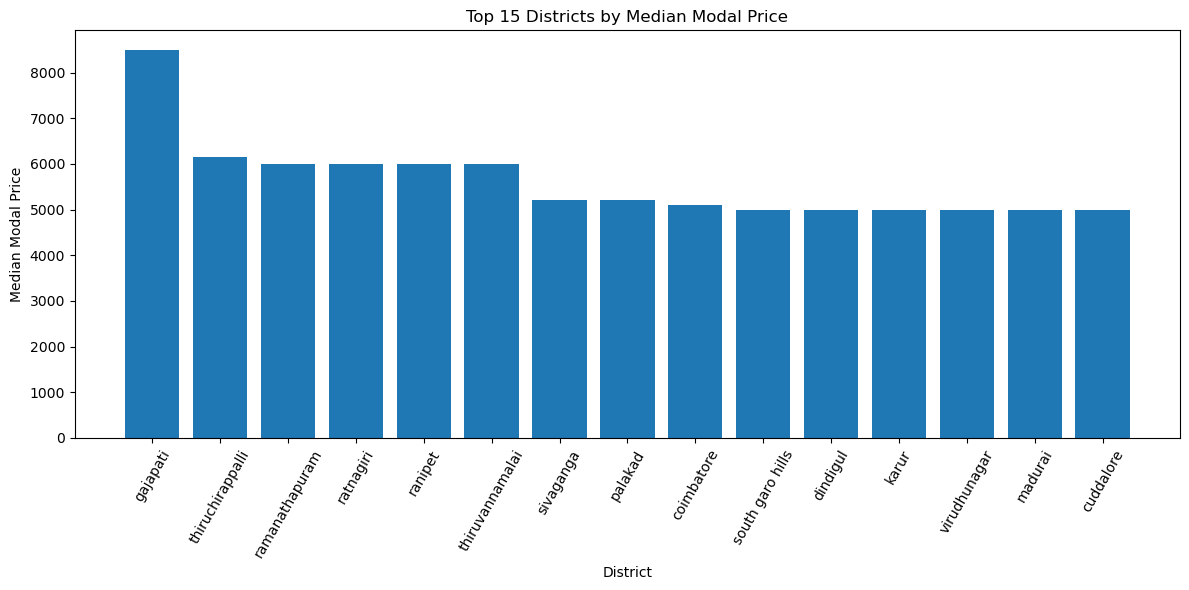

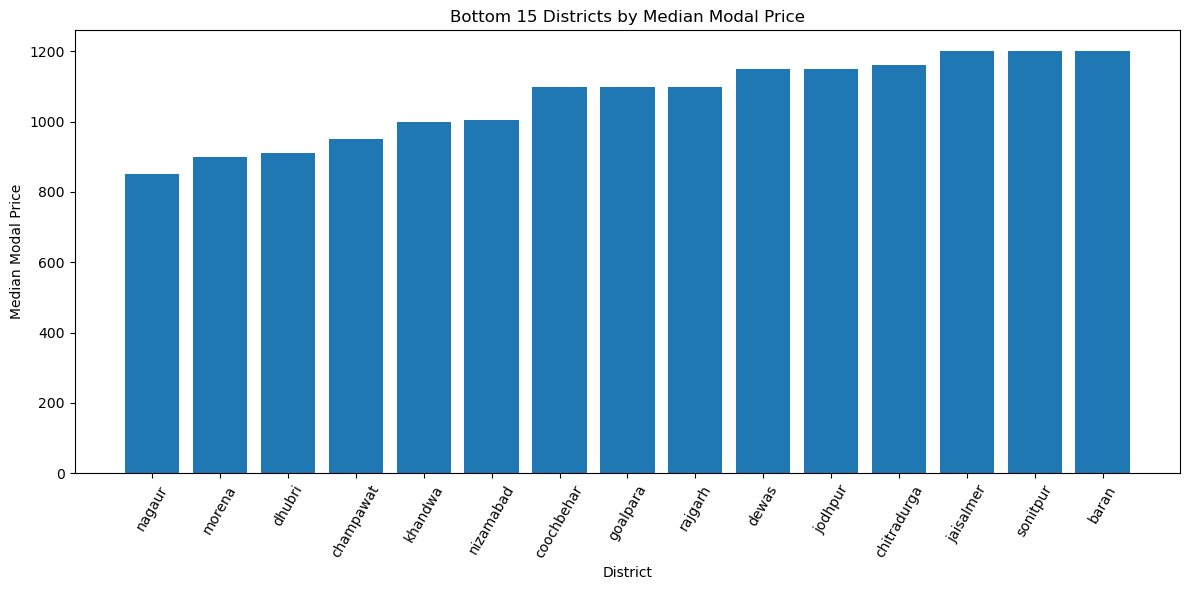

In [45]:


district_price = (
    eda_df
    .groupby("District", as_index=False)
    .agg(
        Median_Price=("Median_Modal_Price", "median"),
        Mean_Price=("Median_Modal_Price", "mean"),
        Record_Count=("Median_Modal_Price", "count")
    )
)

# Top 15 districts
top_15_districts = (
    district_price
    .sort_values("Median_Price", ascending=False)
    .head(15)
)

# Bottom 15 districts
bottom_15_districts = (
    district_price
    .sort_values("Median_Price", ascending=True)
    .head(15)
)

print("Top 15 districts by median modal price:")
display(top_15_districts)

print("\nBottom 15 districts by median modal price:")
display(bottom_15_districts)

# Plot top 15
plt.figure(figsize=(12, 6))

plt.bar(
    top_15_districts["District"],
    top_15_districts["Median_Price"]
)

plt.xlabel("District")
plt.ylabel("Median Modal Price")
plt.title("Top 15 Districts by Median Modal Price")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Plot bottom 15
plt.figure(figsize=(12, 6))

plt.bar(
    bottom_15_districts["District"],
    bottom_15_districts["Median_Price"]
)

plt.xlabel("District")
plt.ylabel("Median Modal Price")
plt.title("Bottom 15 Districts by Median Modal Price")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

Commodity-wise price volatility:


,Commodity,Mean_Price,Std_Price,CV_Percent
3,Tomato,4057.252164,3992.214255,98.396996
0,Onion,2583.747518,1748.076743,67.656639
1,Potato,1859.509963,1096.448165,58.964361
2,Rice,3605.806511,850.566221,23.588793
4,Wheat,2463.748793,335.200523,13.605304


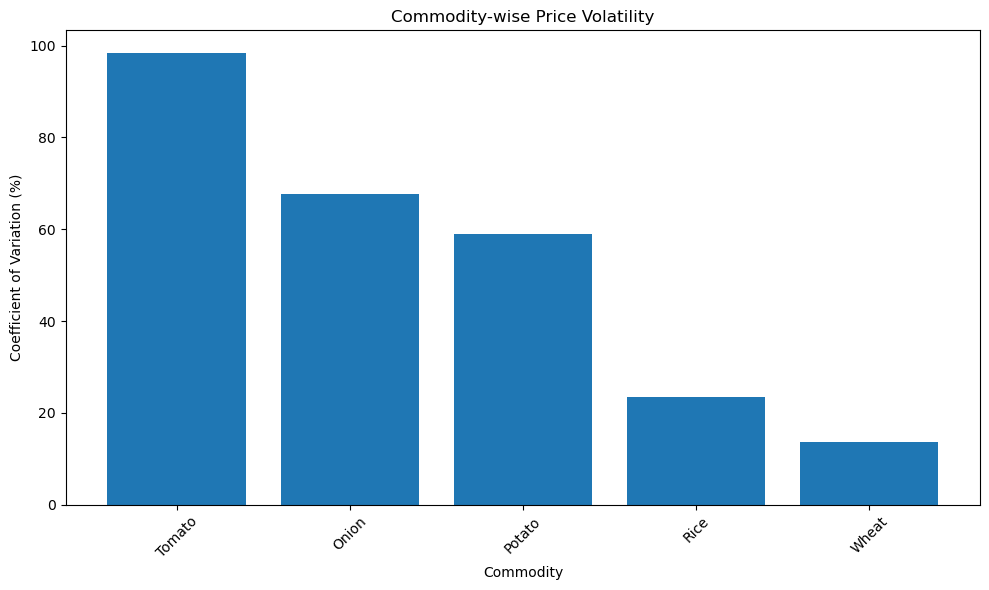

In [46]:

volatility_df = (
    eda_df
    .groupby("Commodity", as_index=False)
    .agg(
        Mean_Price=("Median_Modal_Price", "mean"),
        Std_Price=("Median_Modal_Price", "std")
    )
)

# Coefficient of Variation (CV)
volatility_df["CV_Percent"] = (
    volatility_df["Std_Price"] /
    volatility_df["Mean_Price"]
) * 100

volatility_df = volatility_df.sort_values(
    "CV_Percent",
    ascending=False
)

print("Commodity-wise price volatility:")
display(volatility_df)

# Plot
plt.figure(figsize=(10, 6))

plt.bar(
    volatility_df["Commodity"],
    volatility_df["CV_Percent"]
)

plt.xlabel("Commodity")
plt.ylabel("Coefficient of Variation (%)")
plt.title("Commodity-wise Price Volatility")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Monthly seasonal price pattern:


,Month,Median_Price
0,1,1800.0
1,2,1650.0
2,3,1650.0
3,4,1647.5
4,5,1650.0
5,6,1600.0
6,7,2300.0
7,8,2345.0
8,9,2325.0
9,10,2360.0


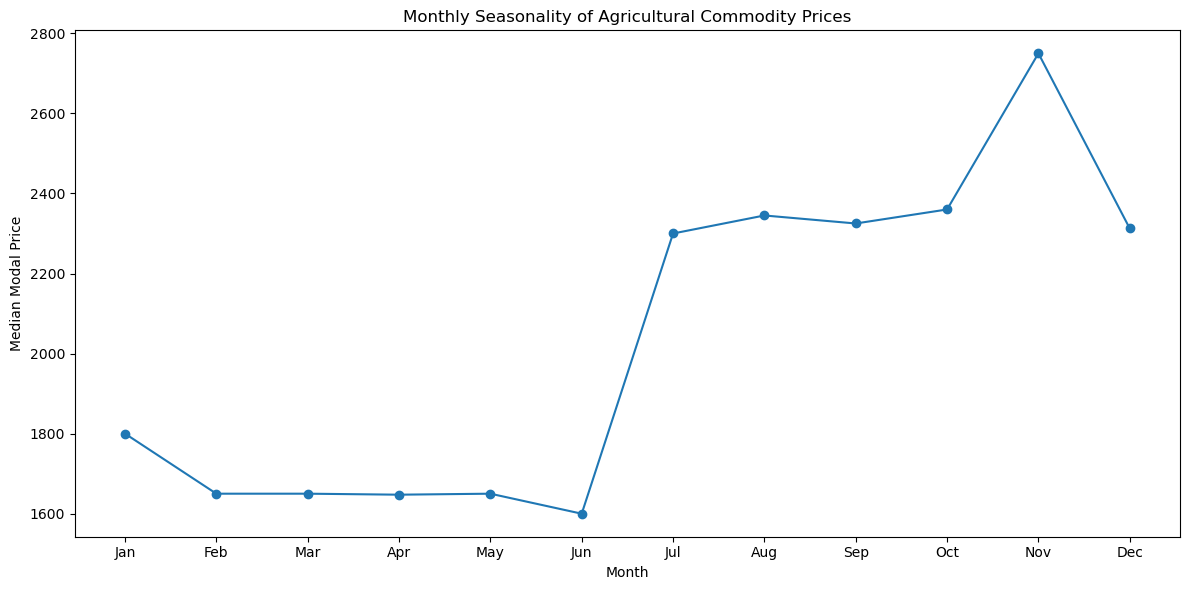

In [47]:
# STEP 9 — Part 7: Seasonality Analysis

# Extract month from weekly date
eda_df["Month"] = eda_df["Week"].dt.month

# Calculate median modal price for each month
monthly_seasonality = (
    eda_df
    .groupby("Month", as_index=False)
    .agg(
        Median_Price=("Median_Modal_Price", "median")
    )
)

print("Monthly seasonal price pattern:")
display(monthly_seasonality)

# Plot seasonal pattern
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_seasonality["Month"],
    monthly_seasonality["Median_Price"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Median Modal Price")
plt.title("Monthly Seasonality of Agricultural Commodity Prices")

plt.xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.tight_layout()
plt.show()

Weather–Price Correlation Matrix:


,Median_Modal_Price,Total_Rainfall,Mean_Temperature,Mean_Humidity
Median_Modal_Price,1.000000,0.172901,0.003290,0.243381
Total_Rainfall,0.172901,1.000000,0.111666,0.497506
Mean_Temperature,0.003290,0.111666,1.000000,-0.315664
Mean_Humidity,0.243381,0.497506,-0.315664,1.000000



Correlation with Median Modal Price:


Mean_Humidity       0.243381
Total_Rainfall      0.172901
Mean_Temperature    0.003290
Name: Median_Modal_Price, dtype: float64

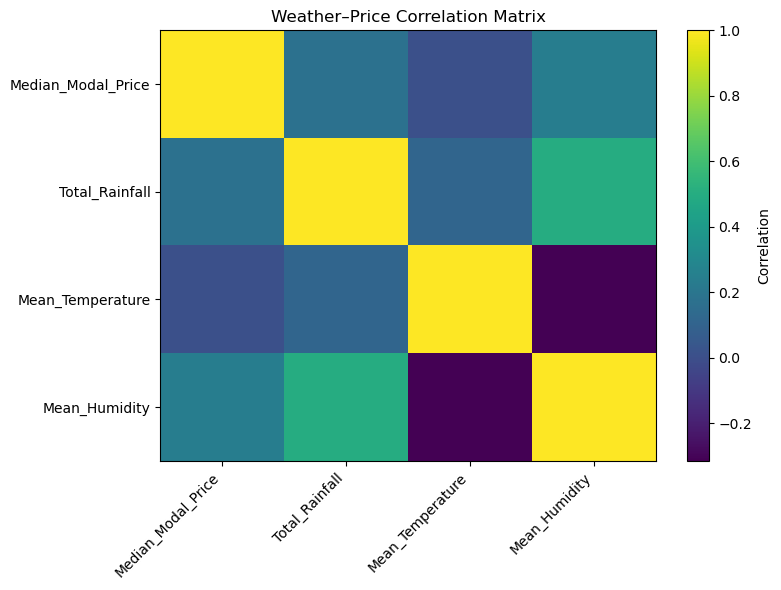

In [48]:


correlation_df = eda_df[
    [
        "Median_Modal_Price",
        "Total_Rainfall",
        "Mean_Temperature",
        "Mean_Humidity"
    ]
].corr()

print("Weather–Price Correlation Matrix:")
display(correlation_df)

# Correlation of weather variables with price
price_weather_corr = (
    correlation_df["Median_Modal_Price"]
    .drop("Median_Modal_Price")
    .sort_values(ascending=False)
)

print("\nCorrelation with Median Modal Price:")
display(price_weather_corr)

# Visualize correlation matrix
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_df,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_df.columns)),
    correlation_df.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_df.columns)),
    correlation_df.columns
)

plt.title("Weather–Price Correlation Matrix")

plt.tight_layout()
plt.show()

In [49]:
eda_df["Month"] = eda_df["Week"].dt.month

Monthly Price Pattern:


,Month,Median_Price
0,1,1800.0
1,2,1650.0
2,3,1650.0
3,4,1647.5
4,5,1650.0
5,6,1600.0
6,7,2300.0
7,8,2345.0
8,9,2325.0
9,10,2360.0



Weekly Price Pattern:


,Week_Number,Median_Price
0,1,1910.00
1,2,1852.50
2,3,1800.00
3,4,1750.00
4,5,1600.00
5,6,1800.00
6,7,1525.00
7,8,1600.00
8,9,1675.00
9,10,1700.00


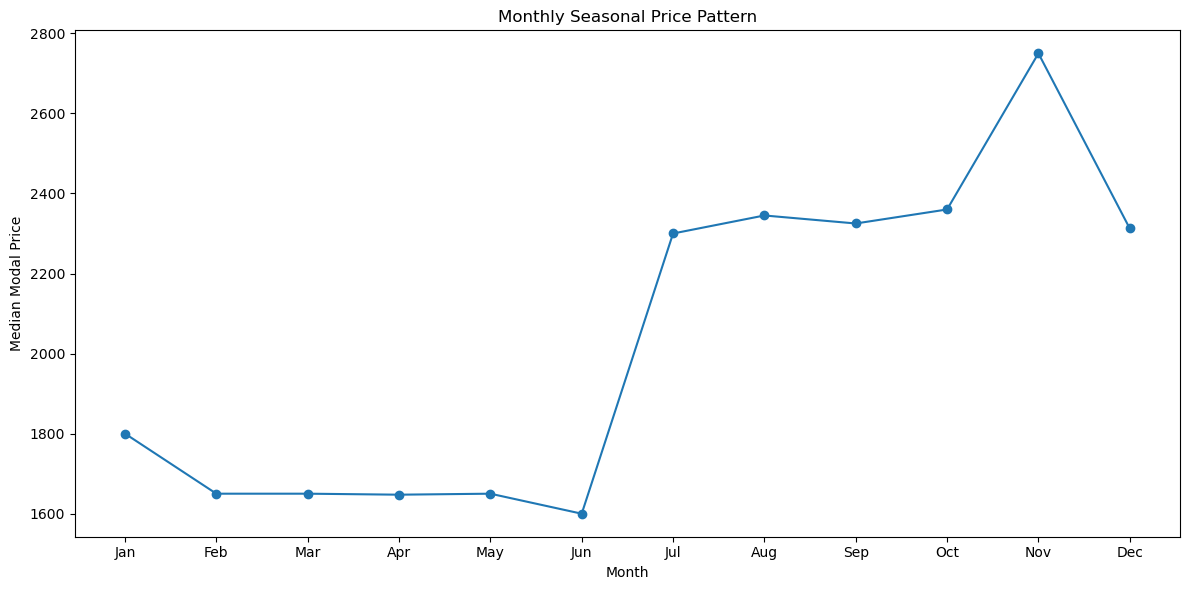

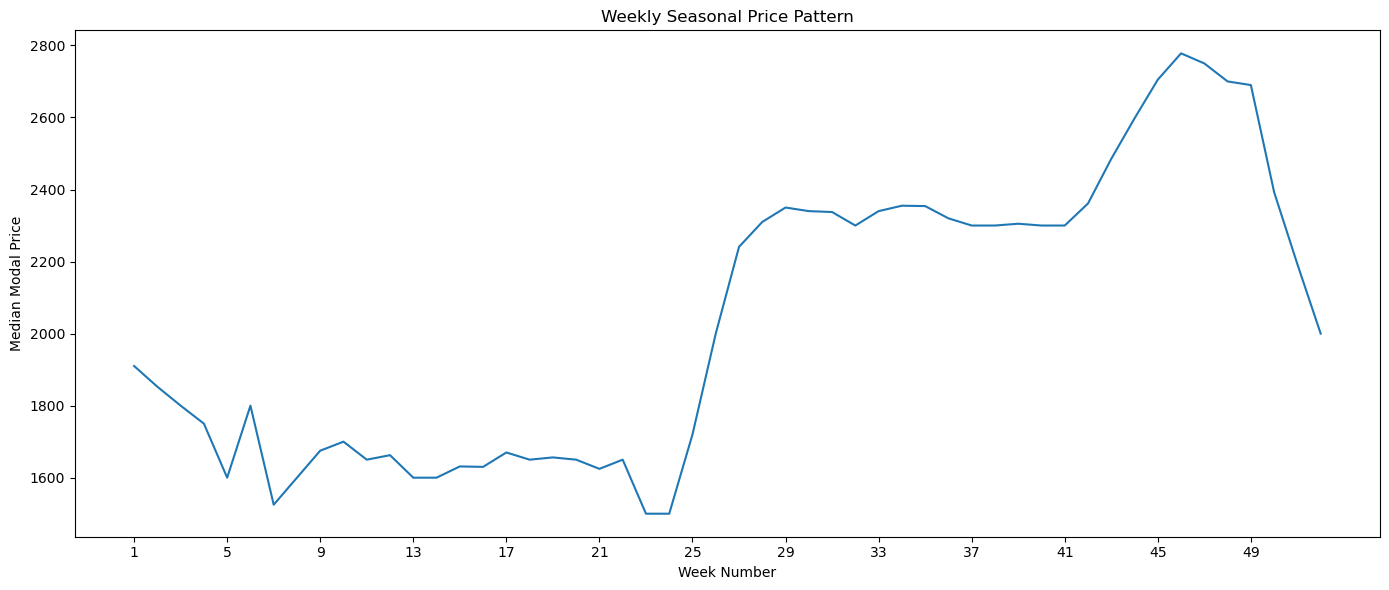

In [50]:


monthly_pattern = (
    eda_df
    .groupby("Month", as_index=False)
    .agg(
        Median_Price=("Median_Modal_Price", "median")
    )
)

print("Monthly Price Pattern:")
display(monthly_pattern)


# -----------------------------------------
# WEEKLY PATTERN
# -----------------------------------------

eda_df["Week_Number"] = eda_df["Week"].dt.isocalendar().week.astype(int)

weekly_pattern = (
    eda_df
    .groupby("Week_Number", as_index=False)
    .agg(
        Median_Price=("Median_Modal_Price", "median")
    )
)

print("\nWeekly Price Pattern:")
display(weekly_pattern)


# -----------------------------------------
# MONTHLY PLOT
# -----------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_pattern["Month"],
    monthly_pattern["Median_Price"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Median Modal Price")
plt.title("Monthly Seasonal Price Pattern")

plt.xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun",
        "Jul", "Aug", "Sep",
        "Oct", "Nov", "Dec"
    ]
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(14, 6))

plt.plot(
    weekly_pattern["Week_Number"],
    weekly_pattern["Median_Price"]
)

plt.xlabel("Week Number")
plt.ylabel("Median Modal Price")
plt.title("Weekly Seasonal Price Pattern")

plt.xticks(range(1, 53, 4))

plt.tight_layout()
plt.show()

In [51]:
# STEP 9 — Commodity-wise Monthly Seasonal Pattern

commodity_monthly = (
    eda_df.groupby(["Commodity", "Month"], as_index=False)
    .agg(
        Median_Price=("Median_Modal_Price", "median")
    )
)

print(commodity_monthly.head(20))

   Commodity  Month  Median_Price
0      Onion      1       1900.00
1      Onion      2       2050.00
2      Onion      3       2000.00
3      Onion      4       1650.00
4      Onion      5       1500.00
5      Onion      6       1210.00
6      Onion      7       2250.00
7      Onion      8       2750.00
8      Onion      9       3300.00
9      Onion     10       3500.00
10     Onion     11       4000.00
11     Onion     12       3000.00
12    Potato      1       1238.75
13    Potato      2       1050.00
14    Potato      3       1250.00
15    Potato      4       1500.00
16    Potato      5       1675.00
17    Potato      6       1500.00
18    Potato      7       1950.00
19    Potato      8       2000.00


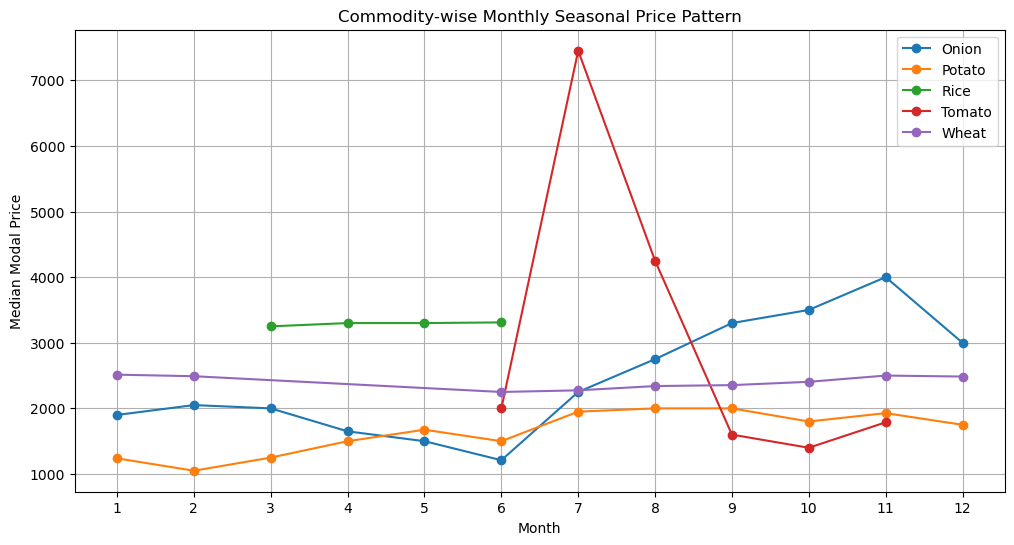

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for commodity in commodity_monthly["Commodity"].unique():
    temp = commodity_monthly[
        commodity_monthly["Commodity"] == commodity
    ]
    
    plt.plot(
        temp["Month"],
        temp["Median_Price"],
        marker="o",
        label=commodity
    )

plt.xlabel("Month")
plt.ylabel("Median Modal Price")
plt.title("Commodity-wise Monthly Seasonal Price Pattern")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.show()

In [53]:
correlation_df = eda_df[
    [
        "Median_Modal_Price",
        "Total_Rainfall",
        "Mean_Temperature",
        "Mean_Humidity"
    ]
].corr()

print(correlation_df)

                    Median_Modal_Price  Total_Rainfall  Mean_Temperature  \
Median_Modal_Price            1.000000        0.172901          0.003290   
Total_Rainfall                0.172901        1.000000          0.111666   
Mean_Temperature              0.003290        0.111666          1.000000   
Mean_Humidity                 0.243381        0.497506         -0.315664   

                    Mean_Humidity  
Median_Modal_Price       0.243381  
Total_Rainfall           0.497506  
Mean_Temperature        -0.315664  
Mean_Humidity            1.000000  


In [54]:
price_weather_corr = (
    correlation_df["Median_Modal_Price"]
    .drop("Median_Modal_Price")
    .sort_values(ascending=False)
)

print("Price–Weather Correlation:")
print(price_weather_corr)

Price–Weather Correlation:
Mean_Humidity       0.243381
Total_Rainfall      0.172901
Mean_Temperature    0.003290
Name: Median_Modal_Price, dtype: float64


In [55]:
# STEP 9 — Weather Lag Relationship

lag_df = eda_df.copy()

# Create weather lags within each State-District-Commodity time series
group_cols = ["State", "District", "Commodity"]

lag_df = lag_df.sort_values(group_cols + ["Week"])

lag_df["Rainfall_Lag_1"] = (
    lag_df.groupby(group_cols)["Total_Rainfall"].shift(1)
)

lag_df["Rainfall_Lag_2"] = (
    lag_df.groupby(group_cols)["Total_Rainfall"].shift(2)
)

lag_df["Temperature_Lag_1"] = (
    lag_df.groupby(group_cols)["Mean_Temperature"].shift(1)
)

lag_df["Temperature_Lag_2"] = (
    lag_df.groupby(group_cols)["Mean_Temperature"].shift(2)
)

lag_df["Humidity_Lag_1"] = (
    lag_df.groupby(group_cols)["Mean_Humidity"].shift(1)
)

lag_df["Humidity_Lag_2"] = (
    lag_df.groupby(group_cols)["Mean_Humidity"].shift(2)
)

In [56]:
lag_correlation = lag_df[
    [
        "Median_Modal_Price",
        "Rainfall_Lag_1",
        "Rainfall_Lag_2",
        "Temperature_Lag_1",
        "Temperature_Lag_2",
        "Humidity_Lag_1",
        "Humidity_Lag_2"
    ]
].corr()["Median_Modal_Price"].drop("Median_Modal_Price")

print("Weather Lag – Price Correlation:")
print(lag_correlation.sort_values(ascending=False))

Weather Lag – Price Correlation:
Humidity_Lag_1       0.250954
Humidity_Lag_2       0.235153
Rainfall_Lag_2       0.196047
Rainfall_Lag_1       0.195140
Temperature_Lag_2    0.066989
Temperature_Lag_1    0.033879
Name: Median_Modal_Price, dtype: float64


In [57]:
market_eda_df = organized_price_df.copy()

market_eda_df["Modal_Price"] = pd.to_numeric(
    market_eda_df["Modal_Price"],
    errors="coerce"
)

# Same state-name corrections jo pehle ki thi
market_eda_df["State"] = market_eda_df["State"].replace(state_mapping)

market_comparison = (
    market_eda_df
    .groupby(["State", "District", "Market"], as_index=False)
    .agg(
        Median_Modal_Price=("Modal_Price", "median"),
        Record_Count=("Modal_Price", "count")
    )
    .sort_values("Median_Modal_Price", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 Markets:")
print(market_comparison.head(15))

print("\nBottom 15 Markets:")
print(market_comparison.tail(15))

Top 15 Markets:
             State            District               Market  \
0            Bihar               patna  Patna (Musallahpur)   
1        Meghalaya    east khasi hills                Sohra   
2           Kerala  thiruvananthapuram           Pothencode   
3           Orissa             bargarh               Sohela   
4           Orissa             bargarh             Padampur   
5           Orissa            rayagada   Rayagada(Muniguda)   
6        Karnataka              tumkur            Madhugiri   
7           Kerala  thiruvananthapuram            Parassala   
8   Andhra Pradesh            adilabad           Mancharial   
9           Kerala              kollam         Sasthamkotta   
10          Orissa            gajapati            Kasinagar   
11          Orissa            gajapati        Parlakhemundi   
12          Kerala  thiruvananthapuram         Neyyatinkara   
13     Maharashtra              nagpur           Parshiwani   
14     Maharashtra              nagpur 

In [58]:
market_comparison = market_comparison.dropna(
    subset=["Median_Modal_Price"]
).reset_index(drop=True)

print("Markets after removing missing prices:", len(market_comparison))

Markets after removing missing prices: 1611


In [59]:
feature_df = merged_df.copy()

feature_df["Week"] = pd.to_datetime(feature_df["Week"])

group_cols = ["State", "District", "Commodity"]

feature_df = feature_df.sort_values(
    group_cols + ["Week"]
).reset_index(drop=True)

feature_df["Price_Lag_1"] = (
    feature_df.groupby(group_cols)["Median_Modal_Price"].shift(1)
)

feature_df["Price_Lag_2"] = (
    feature_df.groupby(group_cols)["Median_Modal_Price"].shift(2)
)

feature_df["Price_Lag_4"] = (
    feature_df.groupby(group_cols)["Median_Modal_Price"].shift(4)
)

print("Feature dataset shape:", feature_df.shape)

print(
    feature_df[
        [
            "State",
            "District",
            "Commodity",
            "Week",
            "Median_Modal_Price",
            "Price_Lag_1",
            "Price_Lag_2",
            "Price_Lag_4"
        ]
    ].head(10)
)

Feature dataset shape: (57866, 13)
            State  District Commodity       Week  Median_Modal_Price  \
0  Andhra Pradesh  adilabad     Onion 2023-12-04              2000.0   
1  Andhra Pradesh  adilabad     Onion 2024-05-13              3250.0   
2  Andhra Pradesh  adilabad     Onion 2024-05-20              2500.0   
3  Andhra Pradesh  adilabad     Onion 2024-06-03              2500.0   
4  Andhra Pradesh  adilabad     Onion 2024-07-01              5000.0   
5  Andhra Pradesh  adilabad     Onion 2024-10-07               825.0   
6  Andhra Pradesh  adilabad     Onion 2024-10-21               743.5   
7  Andhra Pradesh  adilabad     Onion 2024-10-28               793.5   
8  Andhra Pradesh  adilabad     Onion 2024-11-04               950.0   
9  Andhra Pradesh  adilabad     Onion 2025-05-05               700.0   

   Price_Lag_1  Price_Lag_2  Price_Lag_4  
0          NaN          NaN          NaN  
1       2000.0          NaN          NaN  
2       3250.0       2000.0          NaN  


In [60]:
feature_df["Rolling_Mean_4"] = (
    feature_df
    .groupby(group_cols)["Median_Modal_Price"]
    .transform(lambda x: x.shift(1).rolling(4).mean())
)

feature_df["Rolling_Mean_8"] = (
    feature_df
    .groupby(group_cols)["Median_Modal_Price"]
    .transform(lambda x: x.shift(1).rolling(8).mean())
)

print(
    feature_df[
        [
            "State",
            "District",
            "Commodity",
            "Week",
            "Median_Modal_Price",
            "Price_Lag_1",
            "Rolling_Mean_4",
            "Rolling_Mean_8"
        ]
    ].head(12)
)

             State  District Commodity       Week  Median_Modal_Price  \
0   Andhra Pradesh  adilabad     Onion 2023-12-04              2000.0   
1   Andhra Pradesh  adilabad     Onion 2024-05-13              3250.0   
2   Andhra Pradesh  adilabad     Onion 2024-05-20              2500.0   
3   Andhra Pradesh  adilabad     Onion 2024-06-03              2500.0   
4   Andhra Pradesh  adilabad     Onion 2024-07-01              5000.0   
5   Andhra Pradesh  adilabad     Onion 2024-10-07               825.0   
6   Andhra Pradesh  adilabad     Onion 2024-10-21               743.5   
7   Andhra Pradesh  adilabad     Onion 2024-10-28               793.5   
8   Andhra Pradesh  adilabad     Onion 2024-11-04               950.0   
9   Andhra Pradesh  adilabad     Onion 2025-05-05               700.0   
10  Andhra Pradesh  adilabad    Potato 2024-04-22              1062.0   
11  Andhra Pradesh  adilabad    Potato 2024-05-20              4000.0   

    Price_Lag_1  Rolling_Mean_4  Rolling_Mean_8  


In [61]:
feature_df["Rainfall_Lag_1"] = (
    feature_df.groupby(group_cols)["Total_Rainfall"].shift(1)
)

feature_df["Rainfall_Lag_2"] = (
    feature_df.groupby(group_cols)["Total_Rainfall"].shift(2)
)

feature_df["Temperature_Lag_1"] = (
    feature_df.groupby(group_cols)["Mean_Temperature"].shift(1)
)

feature_df["Temperature_Lag_2"] = (
    feature_df.groupby(group_cols)["Mean_Temperature"].shift(2)
)

feature_df["Humidity_Lag_1"] = (
    feature_df.groupby(group_cols)["Mean_Humidity"].shift(1)
)

feature_df["Humidity_Lag_2"] = (
    feature_df.groupby(group_cols)["Mean_Humidity"].shift(2)
)

print(
    feature_df[
        [
            "State",
            "District",
            "Commodity",
            "Week",
            "Total_Rainfall",
            "Rainfall_Lag_1",
            "Rainfall_Lag_2",
            "Mean_Temperature",
            "Temperature_Lag_1",
            "Temperature_Lag_2",
            "Mean_Humidity",
            "Humidity_Lag_1",
            "Humidity_Lag_2"
        ]
    ].head(10)
)

            State  District Commodity       Week  Total_Rainfall  \
0  Andhra Pradesh  adilabad     Onion 2023-12-04             3.6   
1  Andhra Pradesh  adilabad     Onion 2024-05-13             6.9   
2  Andhra Pradesh  adilabad     Onion 2024-05-20             5.1   
3  Andhra Pradesh  adilabad     Onion 2024-06-03            24.1   
4  Andhra Pradesh  adilabad     Onion 2024-07-01            38.7   
5  Andhra Pradesh  adilabad     Onion 2024-10-07            45.4   
6  Andhra Pradesh  adilabad     Onion 2024-10-21             0.0   
7  Andhra Pradesh  adilabad     Onion 2024-10-28             5.9   
8  Andhra Pradesh  adilabad     Onion 2024-11-04             0.0   
9  Andhra Pradesh  adilabad     Onion 2025-05-05             0.0   

   Rainfall_Lag_1  Rainfall_Lag_2  Mean_Temperature  Temperature_Lag_1  \
0             NaN             NaN         22.628571                NaN   
1             3.6             NaN         30.871429          22.628571   
2             6.9            

In [64]:
# Rolling 4-week median
feature_df["Rolling_Median_4"] = (
    feature_df
    .groupby(group_cols)["Median_Modal_Price"]
    .transform(lambda x: x.shift(1).rolling(4).median())
)

# Rolling 8-week standard deviation
feature_df["Rolling_Std_8"] = (
    feature_df
    .groupby(group_cols)["Median_Modal_Price"]
    .transform(lambda x: x.shift(1).rolling(8).std())
)

# Rolling 8-week median
feature_df["Rolling_Median_8"] = (
    feature_df
    .groupby(group_cols)["Median_Modal_Price"]
    .transform(lambda x: x.shift(1).rolling(8).median())
)

In [62]:
feature_df["Year"] = feature_df["Week"].dt.year
feature_df["Month"] = feature_df["Week"].dt.month
feature_df["Week_Number"] = feature_df["Week"].dt.isocalendar().week.astype(int)
feature_df["Quarter"] = feature_df["Week"].dt.quarter

print(
    feature_df[
        ["Week", "Year", "Month", "Week_Number", "Quarter"]
    ].head(10)
)

        Week  Year  Month  Week_Number  Quarter
0 2023-12-04  2023     12           49        4
1 2024-05-13  2024      5           20        2
2 2024-05-20  2024      5           21        2
3 2024-06-03  2024      6           23        2
4 2024-07-01  2024      7           27        3
5 2024-10-07  2024     10           41        4
6 2024-10-21  2024     10           43        4
7 2024-10-28  2024     10           44        4
8 2024-11-04  2024     11           45        4
9 2025-05-05  2025      5           19        2


In [63]:
print("Categorical Features:")
print("State:", feature_df["State"].nunique())
print("District:", feature_df["District"].nunique())
print("Commodity:", feature_df["Commodity"].nunique())

Categorical Features:
State: 29
District: 373
Commodity: 5


In [65]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

feature_df["Season"] = feature_df["Month"].apply(get_season)

In [66]:
forecast_df = feature_df.copy()

forecast_df = forecast_df.sort_values(
    ["State", "District", "Commodity", "Week"]
).reset_index(drop=True)

print("Forecasting dataset shape:", forecast_df.shape)

print("\nTime series groups:",
      forecast_df[["State", "District", "Commodity"]]
      .drop_duplicates()
      .shape[0])

print("\nDate range:")
print(forecast_df["Week"].min(), "to", forecast_df["Week"].max())

Forecasting dataset shape: (57866, 29)

Time series groups: 1185

Date range:
2023-06-05 00:00:00 to 2025-06-09 00:00:00


In [67]:
forecast_df["Target_7D"] = (
    forecast_df
    .groupby(["State", "District", "Commodity"])["Median_Modal_Price"]
    .shift(-1)
)

print(
    forecast_df[
        [
            "State",
            "District",
            "Commodity",
            "Week",
            "Median_Modal_Price",
            "Target_7D"
        ]
    ].head(10)
)

            State  District Commodity       Week  Median_Modal_Price  \
0  Andhra Pradesh  adilabad     Onion 2023-12-04              2000.0   
1  Andhra Pradesh  adilabad     Onion 2024-05-13              3250.0   
2  Andhra Pradesh  adilabad     Onion 2024-05-20              2500.0   
3  Andhra Pradesh  adilabad     Onion 2024-06-03              2500.0   
4  Andhra Pradesh  adilabad     Onion 2024-07-01              5000.0   
5  Andhra Pradesh  adilabad     Onion 2024-10-07               825.0   
6  Andhra Pradesh  adilabad     Onion 2024-10-21               743.5   
7  Andhra Pradesh  adilabad     Onion 2024-10-28               793.5   
8  Andhra Pradesh  adilabad     Onion 2024-11-04               950.0   
9  Andhra Pradesh  adilabad     Onion 2025-05-05               700.0   

   Target_7D  
0     3250.0  
1     2500.0  
2     2500.0  
3     5000.0  
4      825.0  
5      743.5  
6      793.5  
7      950.0  
8      700.0  
9        NaN  


In [68]:
group_cols = ["State", "District", "Commodity"]

# 14-day ahead target
forecast_df["Target_14D"] = (
    forecast_df
    .groupby(group_cols)["Median_Modal_Price"]
    .shift(-2)
)

# 30-day ahead target (~4 weeks ahead)
forecast_df["Target_30D"] = (
    forecast_df
    .groupby(group_cols)["Median_Modal_Price"]
    .shift(-4)
)

In [69]:
print(
    forecast_df[
        [
            "State",
            "District",
            "Commodity",
            "Week",
            "Median_Modal_Price",
            "Target_7D",
            "Target_14D",
            "Target_30D"
        ]
    ].head(10)
)

            State  District Commodity       Week  Median_Modal_Price  \
0  Andhra Pradesh  adilabad     Onion 2023-12-04              2000.0   
1  Andhra Pradesh  adilabad     Onion 2024-05-13              3250.0   
2  Andhra Pradesh  adilabad     Onion 2024-05-20              2500.0   
3  Andhra Pradesh  adilabad     Onion 2024-06-03              2500.0   
4  Andhra Pradesh  adilabad     Onion 2024-07-01              5000.0   
5  Andhra Pradesh  adilabad     Onion 2024-10-07               825.0   
6  Andhra Pradesh  adilabad     Onion 2024-10-21               743.5   
7  Andhra Pradesh  adilabad     Onion 2024-10-28               793.5   
8  Andhra Pradesh  adilabad     Onion 2024-11-04               950.0   
9  Andhra Pradesh  adilabad     Onion 2025-05-05               700.0   

   Target_7D  Target_14D  Target_30D  
0     3250.0      2500.0      5000.0  
1     2500.0      2500.0       825.0  
2     2500.0      5000.0       743.5  
3     5000.0       825.0       793.5  
4      825.0

In [70]:
# 7-day forecasting dataset
forecast_7d = forecast_df.dropna(
    subset=["Target_7D"]
).copy()

# 14-day forecasting dataset
forecast_14d = forecast_df.dropna(
    subset=["Target_14D"]
).copy()

# 30-day forecasting dataset
forecast_30d = forecast_df.dropna(
    subset=["Target_30D"]
).copy()

print("7D dataset shape:", forecast_7d.shape)
print("14D dataset shape:", forecast_14d.shape)
print("30D dataset shape:", forecast_30d.shape)

7D dataset shape: (56681, 32)
14D dataset shape: (55528, 32)
30D dataset shape: (53273, 32)


In [71]:
naive_7d = forecast_7d.copy()

naive_7d["Naive_Prediction"] = (
    naive_7d["Price_Lag_1"]
)

print(
    naive_7d[
        [
            "State",
            "District",
            "Commodity",
            "Week",
            "Median_Modal_Price",
            "Target_7D",
            "Naive_Prediction"
        ]
    ].head(10)
)

             State  District Commodity       Week  Median_Modal_Price  \
0   Andhra Pradesh  adilabad     Onion 2023-12-04              2000.0   
1   Andhra Pradesh  adilabad     Onion 2024-05-13              3250.0   
2   Andhra Pradesh  adilabad     Onion 2024-05-20              2500.0   
3   Andhra Pradesh  adilabad     Onion 2024-06-03              2500.0   
4   Andhra Pradesh  adilabad     Onion 2024-07-01              5000.0   
5   Andhra Pradesh  adilabad     Onion 2024-10-07               825.0   
6   Andhra Pradesh  adilabad     Onion 2024-10-21               743.5   
7   Andhra Pradesh  adilabad     Onion 2024-10-28               793.5   
8   Andhra Pradesh  adilabad     Onion 2024-11-04               950.0   
10  Andhra Pradesh  adilabad    Potato 2024-04-22              1062.0   

    Target_7D  Naive_Prediction  
0      3250.0               NaN  
1      2500.0            2000.0  
2      2500.0            3250.0  
3      5000.0            2500.0  
4       825.0            2

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

eval_7d = naive_7d.dropna(
    subset=["Target_7D", "Naive_Prediction"]
).copy()

mae = mean_absolute_error(
    eval_7d["Target_7D"],
    eval_7d["Naive_Prediction"]
)

rmse = np.sqrt(
    mean_squared_error(
        eval_7d["Target_7D"],
        eval_7d["Naive_Prediction"]
    )
)

mape = np.mean(
    np.abs(
        (eval_7d["Target_7D"] - eval_7d["Naive_Prediction"])
        / eval_7d["Target_7D"]
    )
) * 100

print("Naive 7D Baseline")
print("MAE :", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

Naive 7D Baseline
MAE : 359.40369876458726
RMSE: 1447.2549829358243
MAPE: 15.948634245174084 %


In [73]:
# 14-day Naive baseline
naive_14d = forecast_14d.copy()

naive_14d["Naive_Prediction"] = naive_14d["Price_Lag_1"]

eval_14d = naive_14d.dropna(
    subset=["Target_14D", "Naive_Prediction"]
).copy()


# 30-day Naive baseline
naive_30d = forecast_30d.copy()

naive_30d["Naive_Prediction"] = naive_30d["Price_Lag_1"]

eval_30d = naive_30d.dropna(
    subset=["Target_30D", "Naive_Prediction"]
).copy()


# Metrics function
def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    # Avoid division by zero in MAPE
    non_zero = actual != 0

    mape = np.mean(
        np.abs(
            (actual[non_zero] - predicted[non_zero])
            / actual[non_zero]
        )
    ) * 100

    return mae, rmse, mape


mae_14, rmse_14, mape_14 = calculate_metrics(
    eval_14d["Target_14D"],
    eval_14d["Naive_Prediction"]
)

mae_30, rmse_30, mape_30 = calculate_metrics(
    eval_30d["Target_30D"],
    eval_30d["Naive_Prediction"]
)


print("Naive 14D Baseline")
print("MAE :", mae_14)
print("RMSE:", rmse_14)
print("MAPE:", mape_14, "%")

print("\nNaive 30D Baseline")
print("MAE :", mae_30)
print("RMSE:", rmse_30)
print("MAPE:", mape_30, "%")

Naive 14D Baseline
MAE : 458.82107276805414
RMSE: 1561.662005006136
MAPE: 20.369976767875393 %

Naive 30D Baseline
MAE : 613.2357548634403
RMSE: 1749.4031795053265
MAPE: 28.402252519241134 %


In [74]:
from statsmodels.tsa.arima.model import ARIMA

# Ek time-series select karo
sample_series = (
    forecast_df[
        (forecast_df["State"] == forecast_df["State"].iloc[0]) &
        (forecast_df["District"] == forecast_df["District"].iloc[0]) &
        (forecast_df["Commodity"] == forecast_df["Commodity"].iloc[0])
    ]
    .sort_values("Week")
    .copy()
)

# Target series
y = sample_series["Median_Modal_Price"].dropna().reset_index(drop=True)

print("Series length:", len(y))
print("First 10 values:")
print(y.head(10))

Series length: 10
First 10 values:
0    2000.0
1    3250.0
2    2500.0
3    2500.0
4    5000.0
5     825.0
6     743.5
7     793.5
8     950.0
9     700.0
Name: Median_Modal_Price, dtype: float64


In [75]:
series_lengths = (
    forecast_df
    .groupby(["State", "District", "Commodity"])
    .size()
    .reset_index(name="Weeks")
    .sort_values("Weeks", ascending=False)
    .reset_index(drop=True)
)

print(series_lengths.head(10))

              State    District Commodity  Weeks
0     Uttar Pradesh     auraiya    Potato    106
1     Uttar Pradesh     aligarh    Potato    106
2  Himachal Pradesh       kullu    Potato    106
3  Himachal Pradesh       mandi    Potato    106
4  Himachal Pradesh         una    Potato    106
5   Jammu & Kashmir       jammu    Potato    106
6   Jammu & Kashmir      kathua    Potato    106
7     Uttar Pradesh     sambhal    Potato    106
8     Uttar Pradesh  saharanpur    Potato    106
9     Uttar Pradesh      rampur    Potato    106


In [76]:
# Select the longest time series
sample_state = series_lengths.loc[0, "State"]
sample_district = series_lengths.loc[0, "District"]
sample_commodity = series_lengths.loc[0, "Commodity"]

arima_sample = (
    forecast_df[
        (forecast_df["State"] == sample_state) &
        (forecast_df["District"] == sample_district) &
        (forecast_df["Commodity"] == sample_commodity)
    ]
    .sort_values("Week")
    .copy()
)

# Keep only date and target
arima_sample = arima_sample[
    ["Week", "Median_Modal_Price"]
].dropna()

# 80% train, 20% test
split_index = int(len(arima_sample) * 0.8)

train = arima_sample.iloc[:split_index]
test = arima_sample.iloc[split_index:]

print("Series:", sample_state, "|", sample_district, "|", sample_commodity)
print("Total:", len(arima_sample))
print("Train:", len(train))
print("Test:", len(test))
print("\nTrain date range:", train["Week"].min(), "to", train["Week"].max())
print("Test date range:", test["Week"].min(), "to", test["Week"].max())

Series: Uttar Pradesh | auraiya | Potato
Total: 106
Train: 84
Test: 22

Train date range: 2023-06-05 00:00:00 to 2025-01-06 00:00:00
Test date range: 2025-01-13 00:00:00 to 2025-06-09 00:00:00


In [77]:
# Fit ARIMA model
arima_model = ARIMA(
    train["Median_Modal_Price"],
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:     Median_Modal_Price   No. Observations:                   84
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -465.943
Date:                Wed, 30 Sep 2026   AIC                            937.885
Time:                        21:44:22   BIC                            945.142
Sample:                             0   HQIC                           940.801
                                 - 84                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8376      0.196      4.280      0.000       0.454       1.221
ma.L1         -0.5938      0.262     -2.269      0.023      -1.107      -0.081
sigma2      4387.5366    446.684      9.822      0.0

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


In [78]:
# Set Week as the time-series index
train_arima = train.set_index("Week")["Median_Modal_Price"]
test_arima = test.set_index("Week")["Median_Modal_Price"]

# Set weekly frequency
train_arima = train_arima.asfreq("W-MON")

print("Train index:")
print(train_arima.index)

print("\nTrain length:", len(train_arima))
print("Test length:", len(test_arima))

Train index:
DatetimeIndex(['2023-06-05', '2023-06-12', '2023-06-19', '2023-06-26',
               '2023-07-03', '2023-07-10', '2023-07-17', '2023-07-24',
               '2023-07-31', '2023-08-07', '2023-08-14', '2023-08-21',
               '2023-08-28', '2023-09-04', '2023-09-11', '2023-09-18',
               '2023-09-25', '2023-10-02', '2023-10-09', '2023-10-16',
               '2023-10-23', '2023-10-30', '2023-11-06', '2023-11-13',
               '2023-11-20', '2023-11-27', '2023-12-04', '2023-12-11',
               '2023-12-18', '2023-12-25', '2024-01-01', '2024-01-08',
               '2024-01-15', '2024-01-22', '2024-01-29', '2024-02-05',
               '2024-02-12', '2024-02-19', '2024-02-26', '2024-03-04',
               '2024-03-11', '2024-03-18', '2024-03-25', '2024-04-01',
               '2024-04-08', '2024-04-15', '2024-04-22', '2024-04-29',
               '2024-05-06', '2024-05-13', '2024-05-20', '2024-05-27',
               '2024-06-03', '2024-06-10', '2024-06-17', '2024-0

In [79]:
from statsmodels.tsa.arima.model import ARIMA

# Refit ARIMA with the weekly DatetimeIndex
arima_model = ARIMA(
    train_arima,
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

# Forecast for the 22 test weeks
arima_predictions = arima_result.forecast(
    steps=len(test_arima)
)

# Align predictions with actual test dates
arima_predictions.index = test_arima.index

print("Actual vs ARIMA Predictions:")
print(
    pd.DataFrame({
        "Actual": test_arima,
        "ARIMA_Prediction": arima_predictions
    })
)

Actual vs ARIMA Predictions:
            Actual  ARIMA_Prediction
Week                                
2025-01-13  1310.0       1268.355565
2025-01-20  1215.0       1218.813599
2025-01-27  1100.0       1177.315082
2025-02-03  1010.0       1142.554108
2025-02-10  1000.0       1113.436796
2025-02-17  1000.0       1089.046862
2025-02-24  1010.0       1068.616786
2025-03-03  1100.0       1051.503661
2025-03-10  1240.0       1037.168958
2025-03-17  1240.0       1025.161585
2025-03-24  1260.0       1015.103683
2025-03-31  1260.0       1006.678745
2025-04-07  1260.0        999.621648
2025-04-14  1250.0        993.710315
2025-04-21  1265.0        988.758724
2025-04-28  1210.0        984.611055
2025-05-05  1210.0        981.136786
2025-05-12  1200.0        978.226586
2025-05-19  1210.0        975.788875
2025-05-26  1210.0        973.746942
2025-06-02  1200.0        972.036530
2025-06-09  1190.0        970.603813


In [80]:
# ARIMA evaluation metrics

arima_mae = mean_absolute_error(
    test_arima,
    arima_predictions
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test_arima,
        arima_predictions
    )
)

non_zero = test_arima != 0

arima_mape = np.mean(
    np.abs(
        (test_arima[non_zero] - arima_predictions[non_zero])
        / test_arima[non_zero]
    )
) * 100

print("ARIMA(1,1,1) Results")
print("MAE :", arima_mae)
print("RMSE:", arima_rmse)
print("MAPE:", arima_mape, "%")

ARIMA(1,1,1) Results
MAE : 175.79862549524307
RMSE: 194.96489702021418
MAPE: 14.666975560902976 %


In [81]:
import importlib.util

print("Prophet installed:",
      importlib.util.find_spec("prophet") is not None)

Prophet installed: False


In [82]:
!pip install prophet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 95.0 kB/s eta 0:00:0000:0100:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 84.9 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [prophet]m3/4 [prophet]]


In [83]:
from prophet import Prophet

prophet_train = train[["Week", "Median_Modal_Price"]].copy()

prophet_train = prophet_train.rename(
    columns={
        "Week": "ds",
        "Median_Modal_Price": "y"
    }
)

print(prophet_train.head())
print("\nShape:", prophet_train.shape)

              ds      y
42626 2023-06-05  900.0
42627 2023-06-12  900.0
42628 2023-06-19  900.0
42629 2023-06-26  940.0
42630 2023-07-03  950.0

Shape: (84, 2)


In [84]:
# Create and fit Prophet model
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

print("Prophet model fitted successfully.")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
21:52:45 - cmdstanpy - INFO - Chain [1] start processing
21:52:46 - cmdstanpy - INFO - Chain [1] done processing


Prophet model fitted successfully.


In [85]:
# Create future dates for the test period
future = test[["Week"]].copy()

future = future.rename(
    columns={"Week": "ds"}
)

# Generate forecast
prophet_forecast = prophet_model.predict(future)

# Keep only required columns
prophet_predictions = prophet_forecast[
    ["ds", "yhat"]
].copy()

prophet_predictions = prophet_predictions.rename(
    columns={"yhat": "Prophet_Prediction"}
)

print(prophet_predictions)

           ds  Prophet_Prediction
0  2025-01-13         1567.635171
1  2025-01-20         1581.954439
2  2025-01-27         1567.274727
3  2025-02-03         1563.850909
4  2025-02-10         1607.268880
5  2025-02-17         1694.552606
6  2025-02-24         1796.766031
7  2025-03-03         1893.907743
8  2025-03-10         1987.571664
9  2025-03-17         2082.493975
10 2025-03-24         2168.743072
11 2025-03-31         2230.383025
12 2025-04-07         2266.791391
13 2025-04-14         2295.082596
14 2025-04-21         2329.164364
15 2025-04-28         2364.129150
16 2025-05-05         2387.691389
17 2025-05-12         2402.511804
18 2025-05-19         2426.884814
19 2025-05-26         2470.534057
20 2025-06-02         2518.616947
21 2025-06-09         2549.488160


In [86]:
# Prophet evaluation metrics

prophet_actual = test_arima.values
prophet_pred = prophet_predictions["Prophet_Prediction"].values

prophet_mae = mean_absolute_error(
    prophet_actual,
    prophet_pred
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_actual,
        prophet_pred
    )
)

non_zero = prophet_actual != 0

prophet_mape = np.mean(
    np.abs(
        (prophet_actual[non_zero] - prophet_pred[non_zero])
        / prophet_actual[non_zero]
    )
) * 100

print("Prophet Results")
print("MAE :", prophet_mae)
print("RMSE:", prophet_rmse)
print("MAPE:", prophet_mape, "%")

Prophet Results
MAE : 900.149859715543
RMSE: 951.6183647484282
MAPE: 76.10160363977948 %


In [87]:
# Random Forest feature preparation

rf_data = forecast_df[
    (forecast_df["State"] == sample_state) &
    (forecast_df["District"] == sample_district) &
    (forecast_df["Commodity"] == sample_commodity)
].sort_values("Week").copy()

feature_columns = [
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_4",
    "Rolling_Mean_4",
    "Rolling_Median_4",
    "Rolling_Mean_8",
    "Rolling_Median_8",
    "Rolling_Std_8",
    "Total_Rainfall",
    "Rainfall_Lag_1",
    "Rainfall_Lag_2",
    "Mean_Temperature",
    "Temperature_Lag_1",
    "Temperature_Lag_2",
    "Mean_Humidity",
    "Humidity_Lag_1",
    "Humidity_Lag_2",
    "Year",
    "Month",
    "Week_Number",
    "Quarter"
]

rf_data = rf_data.dropna(
    subset=feature_columns + ["Target_7D"]
).copy()

print("RF data shape:", rf_data.shape)
print("\nFeatures:", len(feature_columns))
print("\nMissing values:")
print(rf_data[feature_columns].isna().sum().sum())

RF data shape: (97, 32)

Features: 21

Missing values:
0


In [88]:
# Time-based train/test split for Random Forest

rf_split_index = int(len(rf_data) * 0.8)

rf_train = rf_data.iloc[:rf_split_index].copy()
rf_test = rf_data.iloc[rf_split_index:].copy()

X_train = rf_train[feature_columns]
y_train = rf_train["Target_7D"]

X_test = rf_test[feature_columns]
y_test = rf_test["Target_7D"]

print("RF Train:", X_train.shape)
print("RF Test :", X_test.shape)

print("\nTrain period:")
print(rf_train["Week"].min(), "to", rf_train["Week"].max())

print("\nTest period:")
print(rf_test["Week"].min(), "to", rf_test["Week"].max())

RF Train: (77, 21)
RF Test : (20, 21)

Train period:
2023-07-31 00:00:00 to 2025-01-13 00:00:00

Test period:
2025-01-20 00:00:00 to 2025-06-02 00:00:00


In [89]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [90]:
# Random Forest predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(rf_predictions)

Random Forest Predictions:
[1290.175  1291.6    1303.4    1245.875  1167.575  1156.1125 1196.5875
 1139.6375 1172.3375 1192.6875 1206.35   1230.45   1231.85   1229.225
 1252.0375 1230.2375 1210.625  1221.2625 1232.7625 1225.9125]


In [91]:
# Random Forest evaluation metrics

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

non_zero = y_test != 0

rf_mape = np.mean(
    np.abs(
        (y_test[non_zero] - rf_predictions[non_zero])
        / y_test[non_zero]
    )
) * 100

print("Random Forest Results")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("MAPE:", rf_mape, "%")

Random Forest Results
MAE : 90.59499999999998
RMSE: 128.45689008136154
MAPE: 8.372505439482536 %


In [92]:
import importlib.util

print(
    "XGBoost installed:",
    importlib.util.find_spec("xgboost") is not None
)

XGBoost installed: True


In [93]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"
)

xgb_model.fit(X_train, y_train)

print("XGBoost trained successfully.")

XGBoost trained successfully.


In [94]:
# XGBoost predictions
xgb_predictions = xgb_model.predict(X_test)

print("XGBoost Predictions:")
print(xgb_predictions)

XGBoost Predictions:
[1238.919  1247.9984 1277.036  1287.028  1171.294  1178.6353 1320.382
 1281.3131 1244.478  1306.5735 1397.1714 1405.2953 1335.0421 1287.7126
 1295.1094 1294.4202 1309.4056 1290.227  1292.4868 1292.8041]


In [95]:
# XGBoost evaluation metrics

xgb_mae = mean_absolute_error(
    y_test,
    xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_predictions
    )
)

non_zero = y_test != 0

xgb_mape = np.mean(
    np.abs(
        (y_test[non_zero] - xgb_predictions[non_zero])
        / y_test[non_zero]
    )
) * 100

print("XGBoost Results")
print("MAE :", xgb_mae)
print("RMSE:", xgb_rmse)
print("MAPE:", xgb_mape, "%")

XGBoost Results
MAE : 117.96878051757812
RMSE: 138.44311142273045
MAPE: 10.591203330018677 %


In [96]:
model_results = pd.DataFrame({
    "Model": [
        "Naive",
        "ARIMA(1,1,1)",
        "Prophet",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        359.40369876458726,
        arima_mae,
        prophet_mae,
        rf_mae,
        xgb_mae
    ],
    "RMSE": [
        1447.2549829358243,
        arima_rmse,
        prophet_rmse,
        rf_rmse,
        xgb_rmse
    ],
    "MAPE": [
        15.948634245174084,
        arima_mape,
        prophet_mape,
        rf_mape,
        xgb_mape
    ]
})

print(model_results)

           Model         MAE         RMSE       MAPE
0          Naive  359.403699  1447.254983  15.948634
1   ARIMA(1,1,1)  175.798625   194.964897  14.666976
2        Prophet  900.149860   951.618365  76.101604
3  Random Forest   90.595000   128.456890   8.372505
4        XGBoost  117.968781   138.443111  10.591203


In [97]:
latest_row = rf_data.sort_values("Week").iloc[-1:]

print("Latest Week:", latest_row["Week"].iloc[0])
print("Latest Price:", latest_row["Median_Modal_Price"].iloc[0])

Latest Week: 2025-06-02 00:00:00
Latest Price: 1200.0


In [98]:
# 7-day future forecast using Random Forest

latest_features = latest_row[feature_columns]

rf_7d_forecast = rf_model.predict(latest_features)[0]

print("7-Day Forecast")
print("Forecast Week:", latest_row["Week"].iloc[0] + pd.Timedelta(days=7))
print("Predicted Price:", rf_7d_forecast)

7-Day Forecast
Forecast Week: 2025-06-09 00:00:00
Predicted Price: 1225.9125


In [99]:
rf_14d_data = forecast_df[
    (forecast_df["State"] == sample_state) &
    (forecast_df["District"] == sample_district) &
    (forecast_df["Commodity"] == sample_commodity)
].sort_values("Week").copy()

rf_14d_data = rf_14d_data.dropna(
    subset=feature_columns + ["Target_14D"]
).copy()

print("14D RF data shape:", rf_14d_data.shape)
print("Missing values:", 
      rf_14d_data[feature_columns].isna().sum().sum())

14D RF data shape: (96, 32)
Missing values: 0


In [100]:
# Time-based split for 14D forecasting

rf_14d_split = int(len(rf_14d_data) * 0.8)

rf_14d_train = rf_14d_data.iloc[:rf_14d_split].copy()
rf_14d_test = rf_14d_data.iloc[rf_14d_split:].copy()

X_train_14d = rf_14d_train[feature_columns]
y_train_14d = rf_14d_train["Target_14D"]

X_test_14d = rf_14d_test[feature_columns]
y_test_14d = rf_14d_test["Target_14D"]

print("14D Train:", X_train_14d.shape)
print("14D Test :", X_test_14d.shape)

print("\nTrain period:")
print(rf_14d_train["Week"].min(), "to", rf_14d_train["Week"].max())

print("\nTest period:")
print(rf_14d_test["Week"].min(), "to", rf_14d_test["Week"].max())

14D Train: (76, 21)
14D Test : (20, 21)

Train period:
2023-07-31 00:00:00 to 2025-01-06 00:00:00

Test period:
2025-01-13 00:00:00 to 2025-05-26 00:00:00


In [101]:
from sklearn.ensemble import RandomForestRegressor

rf_14d_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_14d_model.fit(X_train_14d, y_train_14d)

rf_14d_predictions = rf_14d_model.predict(X_test_14d)

print("14D Random Forest training complete.")
print("Number of predictions:", len(rf_14d_predictions))

14D Random Forest training complete.
Number of predictions: 20


In [102]:
mae_14d = mean_absolute_error(y_test_14d, rf_14d_predictions)

rmse_14d = np.sqrt(
    mean_squared_error(y_test_14d, rf_14d_predictions)
)

mape_14d = np.mean(
    np.abs((y_test_14d - rf_14d_predictions) / y_test_14d)
) * 100

print("Random Forest 14D")
print("MAE :", mae_14d)
print("RMSE:", rmse_14d)
print("MAPE:", mape_14d, "%")

Random Forest 14D
MAE : 191.50625
RMSE: 217.0410451893259
MAPE: 17.006681527651356 %


In [103]:
# 14-day future forecast using Random Forest

latest_features_14d = latest_row[feature_columns]

rf_14d_forecast = rf_14d_model.predict(latest_features_14d)[0]

print("14-Day Forecast")
print("Forecast Week:", latest_row["Week"].iloc[0] + pd.Timedelta(days=14))
print("Predicted Price:", rf_14d_forecast)

14-Day Forecast
Forecast Week: 2025-06-16 00:00:00
Predicted Price: 1405.5125


In [104]:
rf_30d_data = forecast_df[
    (forecast_df["State"] == sample_state) &
    (forecast_df["District"] == sample_district) &
    (forecast_df["Commodity"] == sample_commodity)
].sort_values("Week").copy()

rf_30d_data = rf_30d_data.dropna(
    subset=feature_columns + ["Target_30D"]
).copy()

print("30D RF data shape:", rf_30d_data.shape)
print(
    "Missing values:",
    rf_30d_data[feature_columns].isna().sum().sum()
)

30D RF data shape: (94, 32)
Missing values: 0


In [105]:
# Time-based split for 30D forecasting

rf_30d_split = int(len(rf_30d_data) * 0.8)

rf_30d_train = rf_30d_data.iloc[:rf_30d_split].copy()
rf_30d_test = rf_30d_data.iloc[rf_30d_split:].copy()

X_train_30d = rf_30d_train[feature_columns]
y_train_30d = rf_30d_train["Target_30D"]

X_test_30d = rf_30d_test[feature_columns]
y_test_30d = rf_30d_test["Target_30D"]

print("30D Train:", X_train_30d.shape)
print("30D Test :", X_test_30d.shape)

print("\nTrain period:")
print(rf_30d_train["Week"].min(), "to", rf_30d_train["Week"].max())

print("\nTest period:")
print(rf_30d_test["Week"].min(), "to", rf_30d_test["Week"].max())

30D Train: (75, 21)
30D Test : (19, 21)

Train period:
2023-07-31 00:00:00 to 2024-12-30 00:00:00

Test period:
2025-01-06 00:00:00 to 2025-05-12 00:00:00


In [106]:
from sklearn.ensemble import RandomForestRegressor

rf_30d_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_30d_model.fit(X_train_30d, y_train_30d)

rf_30d_predictions = rf_30d_model.predict(X_test_30d)

print("30D Random Forest training complete.")
print("Number of predictions:", len(rf_30d_predictions))

30D Random Forest training complete.
Number of predictions: 19


In [107]:
mae_30d = mean_absolute_error(y_test_30d, rf_30d_predictions)

rmse_30d = np.sqrt(
    mean_squared_error(y_test_30d, rf_30d_predictions)
)

mape_30d = np.mean(
    np.abs((y_test_30d - rf_30d_predictions) / y_test_30d)
) * 100

print("Random Forest 30D")
print("MAE :", mae_30d)
print("RMSE:", rmse_30d)
print("MAPE:", mape_30d, "%")

Random Forest 30D
MAE : 300.44671052631577
RMSE: 317.6775689606109
MAPE: 25.764275100295947 %


In [108]:
# 30-day future forecast using Random Forest

latest_features_30d = latest_row[feature_columns]

rf_30d_forecast = rf_30d_model.predict(latest_features_30d)[0]

print("30-Day Forecast")
print("Forecast Week:", latest_row["Week"].iloc[0] + pd.Timedelta(days=30))
print("Predicted Price:", rf_30d_forecast)

30-Day Forecast
Forecast Week: 2025-07-02 00:00:00
Predicted Price: 1661.825


In [109]:
# Save final feature-engineered dataset

feature_df.to_csv(
    "agricultural_market_final_features.csv",
    index=False
)

print("File saved successfully.")
print("Shape:", feature_df.shape)

File saved successfully.
Shape: (57866, 29)


In [110]:
import os

print(os.path.abspath("agricultural_market_final_features.csv"))

/Users/snehasharma/AGRICULTURE PROJECT/agricultural_market_final_features.csv


In [111]:
# Global forecasting dataset for all State + District + Commodity series

global_rf_data = forecast_df.dropna(
    subset=feature_columns + ["Target_7D"]
).copy()

print("Global 7D dataset:", global_rf_data.shape)
print("Number of series:",
      global_rf_data[["State", "District", "Commodity"]]
      .drop_duplicates()
      .shape[0])

Global 7D dataset: (47931, 32)
Number of series: 939


In [112]:
# Global 7D time-based split

global_rf_data = global_rf_data.sort_values("Week").reset_index(drop=True)

split_index = int(len(global_rf_data) * 0.8)

global_train = global_rf_data.iloc[:split_index].copy()
global_test = global_rf_data.iloc[split_index:].copy()

X_train_global = global_train[feature_columns]
y_train_global = global_train["Target_7D"]

X_test_global = global_test[feature_columns]
y_test_global = global_test["Target_7D"]

print("Global Train:", X_train_global.shape)
print("Global Test :", X_test_global.shape)

print("\nTrain period:")
print(global_train["Week"].min(), "to", global_train["Week"].max())

print("\nTest period:")
print(global_test["Week"].min(), "to", global_test["Week"].max())

Global Train: (38344, 21)
Global Test : (9587, 21)

Train period:
2023-07-31 00:00:00 to 2025-01-06 00:00:00

Test period:
2025-01-06 00:00:00 to 2025-06-02 00:00:00


In [113]:
from sklearn.ensemble import RandomForestRegressor

global_rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

global_rf_model.fit(X_train_global, y_train_global)

global_rf_predictions = global_rf_model.predict(X_test_global)

print("Global 7D Random Forest training complete.")
print("Number of predictions:", len(global_rf_predictions))

Global 7D Random Forest training complete.
Number of predictions: 9587


In [114]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

global_mae_7d = mean_absolute_error(
    y_test_global,
    global_rf_predictions
)

global_rmse_7d = np.sqrt(
    mean_squared_error(
        y_test_global,
        global_rf_predictions
    )
)

global_mape_7d = np.mean(
    np.abs(
        (y_test_global - global_rf_predictions)
        / y_test_global
    )
) * 100

print("Global Random Forest 7D")
print("MAE :", global_mae_7d)
print("RMSE:", global_rmse_7d)
print("MAPE:", global_mape_7d, "%")

Global Random Forest 7D
MAE : 297.64986221352177
RMSE: 1579.480755743624
MAPE: 18.45509469710053 %


In [115]:
global_rf_14d_data = forecast_df.dropna(
    subset=feature_columns + ["Target_14D"]
).copy()

global_rf_14d_data = global_rf_14d_data.sort_values(
    "Week"
).reset_index(drop=True)

print("Global 14D dataset:", global_rf_14d_data.shape)

print(
    "Number of series:",
    global_rf_14d_data[
        ["State", "District", "Commodity"]
    ].drop_duplicates().shape[0]
)

Global 14D dataset: (46992, 32)
Number of series: 901


In [116]:
split_index = int(len(global_rf_14d_data) * 0.8)

global_train_14d = global_rf_14d_data.iloc[:split_index].copy()
global_test_14d = global_rf_14d_data.iloc[split_index:].copy()

X_train_global_14d = global_train_14d[feature_columns]
y_train_global_14d = global_train_14d["Target_14D"]

X_test_global_14d = global_test_14d[feature_columns]
y_test_global_14d = global_test_14d["Target_14D"]

print("Global 14D Train:", X_train_global_14d.shape)
print("Global 14D Test :", X_test_global_14d.shape)

print("Train period:",
      global_train_14d["Week"].min(),
      "to",
      global_train_14d["Week"].max())

print("Test period:",
      global_test_14d["Week"].min(),
      "to",
      global_test_14d["Week"].max())

Global 14D Train: (37593, 21)
Global 14D Test : (9399, 21)
Train period: 2023-07-31 00:00:00 to 2024-12-23 00:00:00
Test period: 2024-12-23 00:00:00 to 2025-05-26 00:00:00


In [117]:
global_rf_model_14d = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

global_rf_model_14d.fit(
    X_train_global_14d,
    y_train_global_14d
)

global_rf_predictions_14d = global_rf_model_14d.predict(
    X_test_global_14d
)

print("Global 14D Random Forest training complete.")
print("Number of predictions:", len(global_rf_predictions_14d))

Global 14D Random Forest training complete.
Number of predictions: 9399


In [118]:
global_mae_14d = mean_absolute_error(
    y_test_global_14d,
    global_rf_predictions_14d
)

global_rmse_14d = np.sqrt(
    mean_squared_error(
        y_test_global_14d,
        global_rf_predictions_14d
    )
)

global_mape_14d = np.mean(
    np.abs(
        (y_test_global_14d - global_rf_predictions_14d)
        / y_test_global_14d
    )
) * 100

print("Global Random Forest 14D")
print("MAE :", global_mae_14d)
print("RMSE:", global_rmse_14d)
print("MAPE:", global_mape_14d, "%")

Global Random Forest 14D
MAE : 374.77687243859873
RMSE: 1586.3319588008455
MAPE: 25.27233516511391 %


In [119]:
global_rf_30d_data = forecast_df.dropna(
    subset=feature_columns + ["Target_30D"]
).copy()

global_rf_30d_data = global_rf_30d_data.sort_values(
    "Week"
).reset_index(drop=True)

print("Global 30D dataset:", global_rf_30d_data.shape)

print(
    "Number of series:",
    global_rf_30d_data[
        ["State", "District", "Commodity"]
    ].drop_duplicates().shape[0]
)

Global 30D dataset: (45198, 32)
Number of series: 888


In [120]:
split_index = int(len(global_rf_30d_data) * 0.8)

global_train_30d = global_rf_30d_data.iloc[:split_index].copy()
global_test_30d = global_rf_30d_data.iloc[split_index:].copy()

X_train_global_30d = global_train_30d[feature_columns]
y_train_global_30d = global_train_30d["Target_30D"]

X_test_global_30d = global_test_30d[feature_columns]
y_test_global_30d = global_test_30d["Target_30D"]

print("Global 30D Train:", X_train_global_30d.shape)
print("Global 30D Test :", X_test_global_30d.shape)

print("Train period:",
      global_train_30d["Week"].min(),
      "to",
      global_train_30d["Week"].max())

print("Test period:",
      global_test_30d["Week"].min(),
      "to",
      global_test_30d["Week"].max())

Global 30D Train: (36158, 21)
Global 30D Test : (9040, 21)
Train period: 2023-07-31 00:00:00 to 2024-12-09 00:00:00
Test period: 2024-12-09 00:00:00 to 2025-05-12 00:00:00


In [121]:
global_rf_model_30d = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

global_rf_model_30d.fit(
    X_train_global_30d,
    y_train_global_30d
)

global_rf_predictions_30d = global_rf_model_30d.predict(
    X_test_global_30d
)

print("Global 30D Random Forest training complete.")
print("Number of predictions:", len(global_rf_predictions_30d))

Global 30D Random Forest training complete.
Number of predictions: 9040


In [122]:
global_mae_30d = mean_absolute_error(
    y_test_global_30d,
    global_rf_predictions_30d
)

global_rmse_30d = np.sqrt(
    mean_squared_error(
        y_test_global_30d,
        global_rf_predictions_30d
    )
)

global_mape_30d = np.mean(
    np.abs(
        (y_test_global_30d - global_rf_predictions_30d)
        / y_test_global_30d
    )
) * 100

print("Global Random Forest 30D")
print("MAE :", global_mae_30d)
print("RMSE:", global_rmse_30d)
print("MAPE:", global_mape_30d, "%")

Global Random Forest 30D
MAE : 537.5234494224792
RMSE: 990.548881889778
MAPE: 38.4260631373705 %


In [123]:
latest_7d = (
    forecast_df
    .sort_values("Week")
    .groupby(["State", "District", "Commodity"], as_index=False)
    .tail(1)
    .copy()
)

latest_7d = latest_7d.dropna(subset=feature_columns).copy()

latest_7d["Forecast_7D"] = global_rf_model.predict(
    latest_7d[feature_columns]
)

forecast_7d_all = latest_7d[
    ["State", "District", "Commodity", "Week",
     "Median_Modal_Price", "Forecast_7D"]
].copy()

forecast_7d_all = forecast_7d_all.rename(
    columns={
        "Week": "Latest_Week",
        "Median_Modal_Price": "Latest_Price"
    }
)

print("7D forecasts generated:", len(forecast_7d_all))
print(forecast_7d_all.head())

7D forecasts generated: 1035
                State          District Commodity Latest_Week  Latest_Price  \
28127       Meghalaya  east khasi hills    Tomato  2023-07-31        5500.0   
25577     Maharashtra            mumbai    Tomato  2023-07-31        9500.0   
38091       Rajasthan        pratapgarh    Tomato  2023-07-31        7900.0   
21397  Madhya Pradesh           khandwa    Tomato  2023-07-31        1600.0   
50808   Uttar Pradesh            mahoba    Tomato  2023-07-31        8250.0   

       Forecast_7D  
28127  4404.467996  
25577  8008.296924  
38091  6160.826303  
21397  2565.872488  
50808  6842.118211  


In [124]:
latest_14d = (
    forecast_df
    .sort_values("Week")
    .groupby(["State", "District", "Commodity"], as_index=False)
    .tail(1)
    .copy()
)

latest_14d = latest_14d.dropna(subset=feature_columns).copy()

latest_14d["Forecast_14D"] = global_rf_model_14d.predict(
    latest_14d[feature_columns]
)

forecast_14d_all = latest_14d[
    ["State", "District", "Commodity", "Week",
     "Median_Modal_Price", "Forecast_14D"]
].copy()

forecast_14d_all = forecast_14d_all.rename(
    columns={
        "Week": "Latest_Week",
        "Median_Modal_Price": "Latest_Price"
    }
)

print("14D forecasts generated:", len(forecast_14d_all))
print(forecast_14d_all.head())

14D forecasts generated: 1035
                State          District Commodity Latest_Week  Latest_Price  \
28127       Meghalaya  east khasi hills    Tomato  2023-07-31        5500.0   
25577     Maharashtra            mumbai    Tomato  2023-07-31        9500.0   
38091       Rajasthan        pratapgarh    Tomato  2023-07-31        7900.0   
21397  Madhya Pradesh           khandwa    Tomato  2023-07-31        1600.0   
50808   Uttar Pradesh            mahoba    Tomato  2023-07-31        8250.0   

       Forecast_14D  
28127   2978.239944  
25577   6798.716613  
38091   4656.958169  
21397   2637.073133  
50808   4749.305356  


In [125]:
latest_30d = (
    forecast_df
    .sort_values("Week")
    .groupby(["State", "District", "Commodity"], as_index=False)
    .tail(1)
    .copy()
)

latest_30d = latest_30d.dropna(subset=feature_columns).copy()

latest_30d["Forecast_30D"] = global_rf_model_30d.predict(
    latest_30d[feature_columns]
)

forecast_30d_all = latest_30d[
    ["State", "District", "Commodity", "Week",
     "Median_Modal_Price", "Forecast_30D"]
].copy()

forecast_30d_all = forecast_30d_all.rename(
    columns={
        "Week": "Latest_Week",
        "Median_Modal_Price": "Latest_Price"
    }
)

print("30D forecasts generated:", len(forecast_30d_all))
print(forecast_30d_all.head())

30D forecasts generated: 1035
                State          District Commodity Latest_Week  Latest_Price  \
28127       Meghalaya  east khasi hills    Tomato  2023-07-31        5500.0   
25577     Maharashtra            mumbai    Tomato  2023-07-31        9500.0   
38091       Rajasthan        pratapgarh    Tomato  2023-07-31        7900.0   
21397  Madhya Pradesh           khandwa    Tomato  2023-07-31        1600.0   
50808   Uttar Pradesh            mahoba    Tomato  2023-07-31        8250.0   

       Forecast_30D  
28127   2472.689529  
25577   4482.157019  
38091   2200.679400  
21397   2786.071092  
50808   2331.627531  


In [126]:
forecast_7d_all.to_csv(
    "forecast_7d_all.csv",
    index=False
)

forecast_14d_all.to_csv(
    "forecast_14d_all.csv",
    index=False
)

forecast_30d_all.to_csv(
    "forecast_30d_all.csv",
    index=False
)

print("All forecast files saved successfully.")

All forecast files saved successfully.


In [127]:
print("Maximum historical week:")
print(feature_df["Week"].max())

print("\nMaximum 7D forecast base week:")
print(forecast_7d_all["Latest_Week"].max())

print("\nMaximum 14D forecast base week:")
print(forecast_14d_all["Latest_Week"].max())

print("\nMaximum 30D forecast base week:")
print(forecast_30d_all["Latest_Week"].max())

Maximum historical week:
2025-06-09 00:00:00

Maximum 7D forecast base week:
2025-06-09 00:00:00

Maximum 14D forecast base week:
2025-06-09 00:00:00

Maximum 30D forecast base week:
2025-06-09 00:00:00
